In [210]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#%pip install plotnine
#%pip install kmodes
from plotnine import *
import plotnine
from kmodes.kprototypes import KPrototypes
import warnings
warnings.filterwarnings('ignore', category = FutureWarning)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
from mlxtend.frequent_patterns import apriori, association_rules

# Data Quality

In [211]:
df = pd.read_excel('Telco_customer_churn.xlsx')

In [212]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [213]:
df['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

Data is clean with only missing values being located in Churn Reason. These values are missing for customers who have not churned. The churn class is heavily imbalanced, with only 26.54% of customers churning.

In [214]:
print(df.dtypes)

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object


In [215]:
# Check for duplicate customers
df['CustomerID'].duplicated().sum()

np.int64(0)

In [216]:
df['Total Charges'].describe()

count    7043.000
unique   6531.000
top        20.200
freq       11.000
Name: Total Charges, dtype: float64

In [217]:
# Check Total Charges to see if it should actually be object
df['Total Charges'].head(50).values

array([108.15, 151.65, 820.5, 3046.05, 5036.3, 528.35, 39.65, 20.15,
       4749.15, 30.2, 1093.1, 316.9, 3549.25, 1105.4, 144.15, 1426.4,
       633.3, 1752.55, 857.25, 79.35, 496.9, 927.35, 113.85, 2514.5,
       7611.85, 5238.9, 2868.15, 1064.65, 229.55, 2135.5, 1502.65, 35.45,
       81.25, 70.45, 563.65, 45.65, 655.5, 1592.35, 273, 2651.2, 242.8,
       5000.2, 1145.7, 503.6, 29.95, 662.65, 1111.65, 24.8, 531, 79.9],
      dtype=object)

Based on these values, Total Charges should be a numeric column rather than an object.

In [218]:
# Convert Total Charges to be numeric instead of object, fill resulting na from blank string with 0
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'] = df['Total Charges'].fillna(0)

In [219]:
# Check unique values per column
print(df.nunique())

CustomerID           7043
Count                   1
Country                 1
State                   1
City                 1129
Zip Code             1652
Lat Long             1652
Latitude             1652
Longitude            1651
Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Tenure Months          73
Phone Service           2
Multiple Lines          3
Internet Service        3
Online Security         3
Online Backup           3
Device Protection       3
Tech Support            3
Streaming TV            3
Streaming Movies        3
Contract                3
Paperless Billing       2
Payment Method          4
Monthly Charges      1585
Total Charges        6531
Churn Label             2
Churn Value             2
Churn Score            85
CLTV                 3438
Churn Reason           20
dtype: int64


In [220]:
# Look at categorical unique values
categorical_cols = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Contract',
    'Paperless Billing',
    'Payment Method',
]

numeric_cols = ['Tenure Months', 'Total Charges', 'Monthly Charges']

for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(df[col].unique())


--- Gender ---
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

--- Senior Citizen ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Partner ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Dependents ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Phone Service ---
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

--- Multiple Lines ---
<StringArray>
['No', 'Yes', 'No phone service']
Length: 3, dtype: str

--- Internet Service ---
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

--- Online Security ---
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

--- Online Backup ---
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

--- Device Protection ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- Tech Support ---
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

--- Streaming TV ---
<StringArray>
['No', 'Yes', 'No internet service'

In [221]:
for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(df[col].value_counts(dropna=False))


--- Gender ---
Gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Senior Citizen ---
Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     5416
Yes    1627
Name: count, dtype: int64

--- Phone Service ---
Phone Service
Yes    6361
No      682
Name: count, dtype: int64

--- Multiple Lines ---
Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- Internet Service ---
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- Online Security ---
Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- Online Backup ---
Online Backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- Device Protection

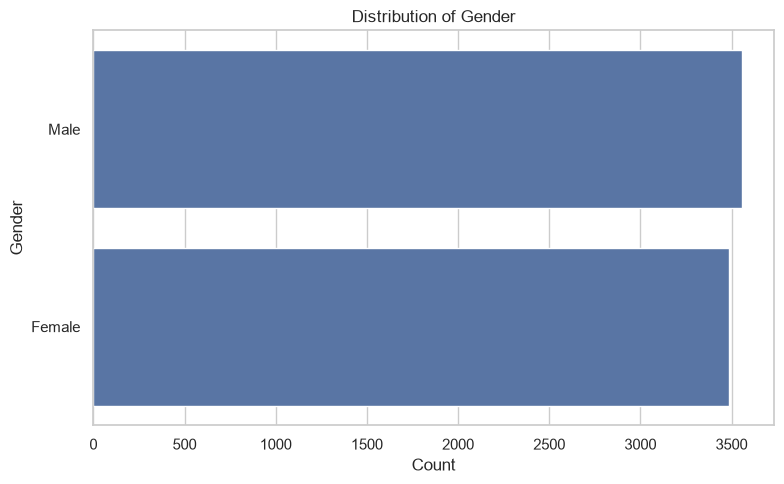

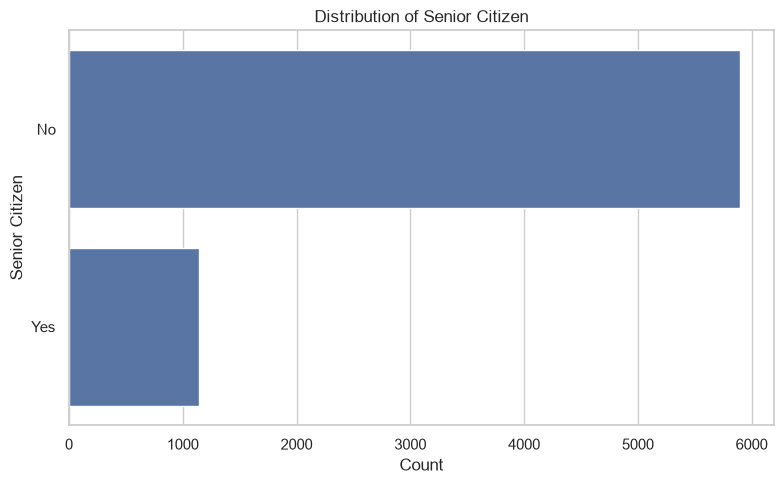

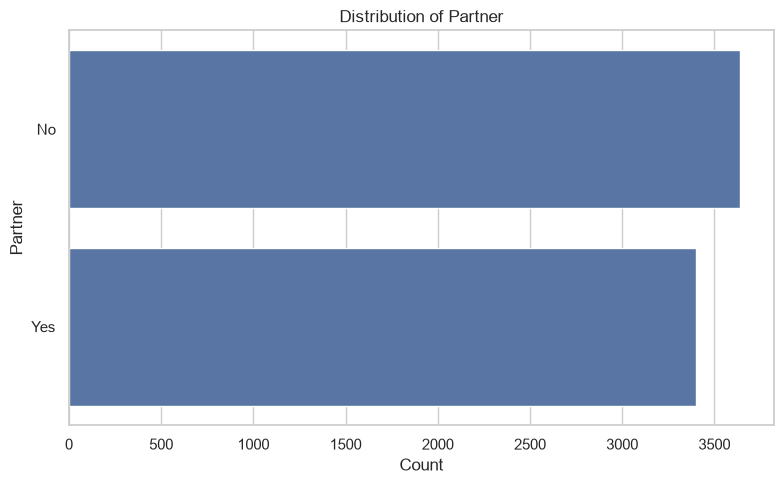

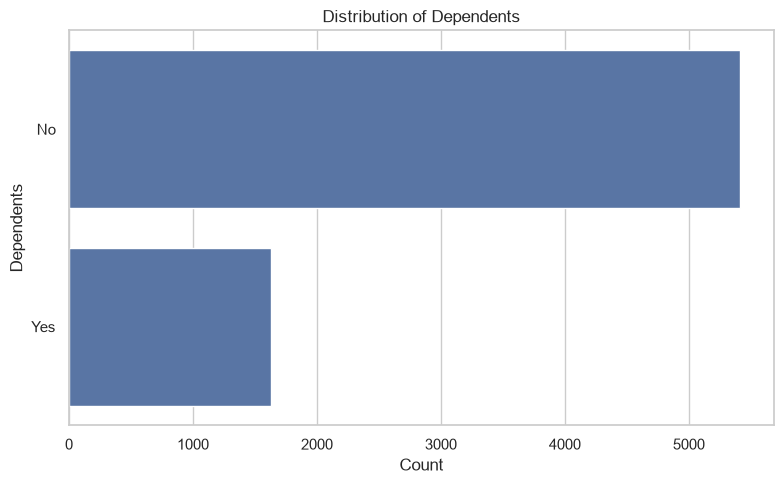

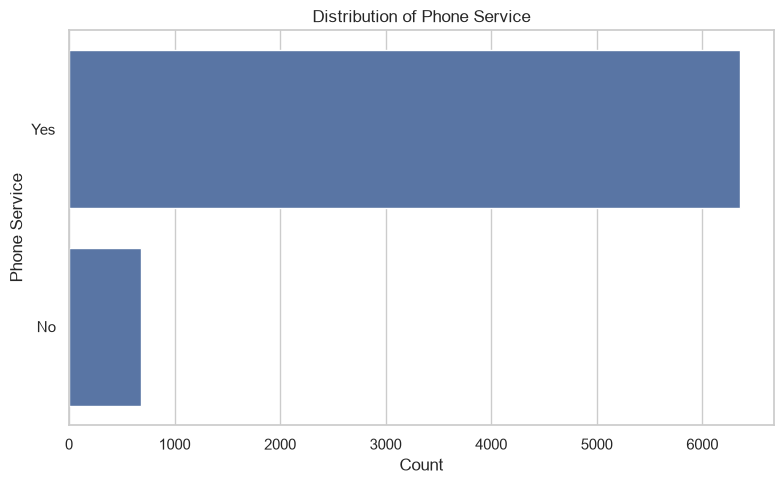

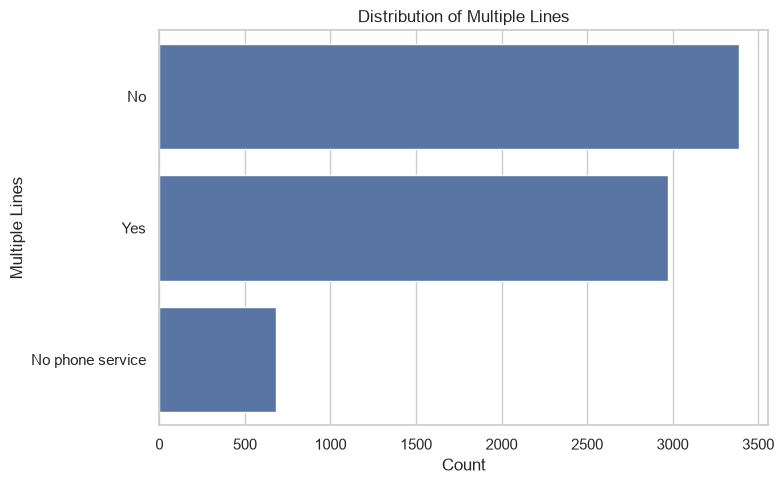

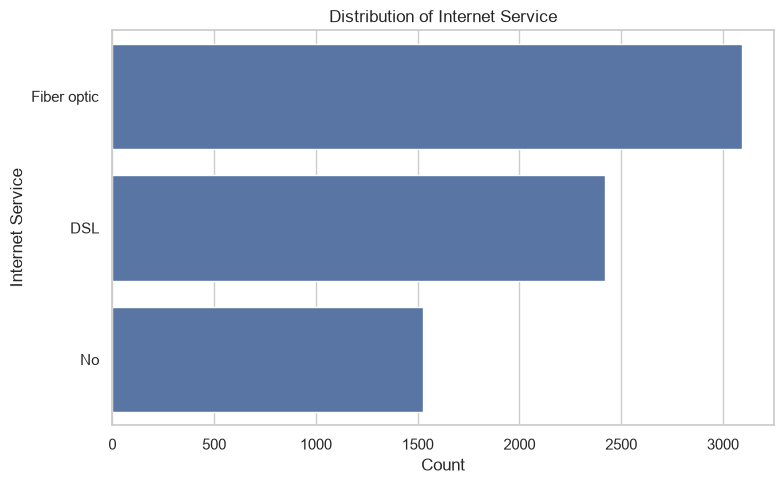

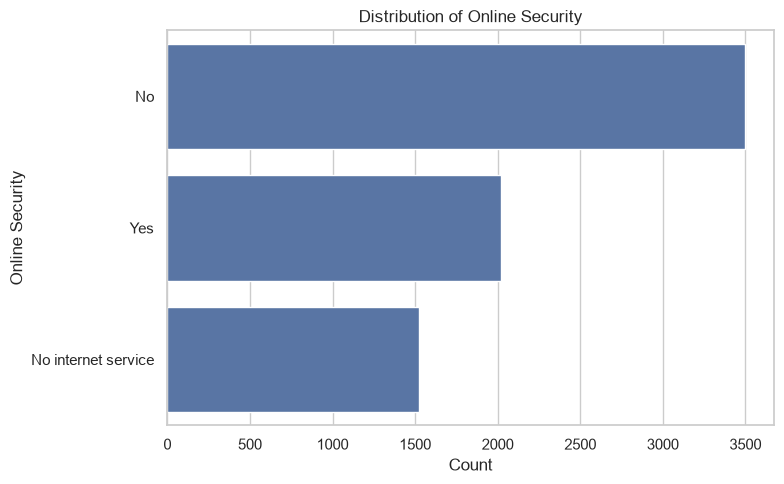

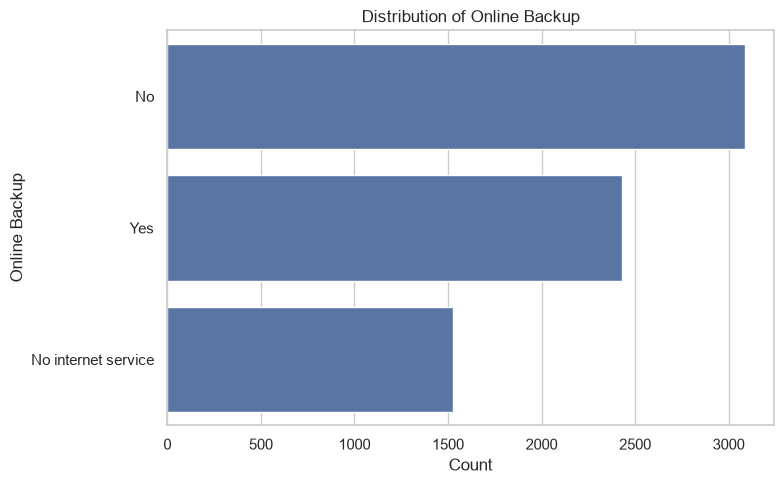

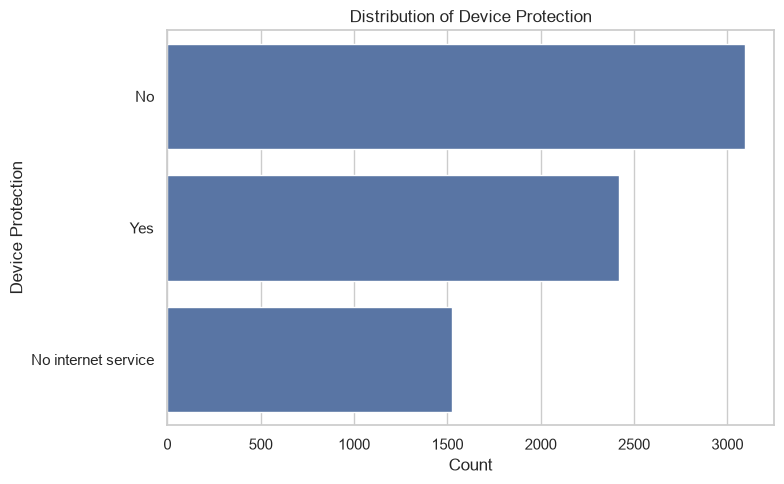

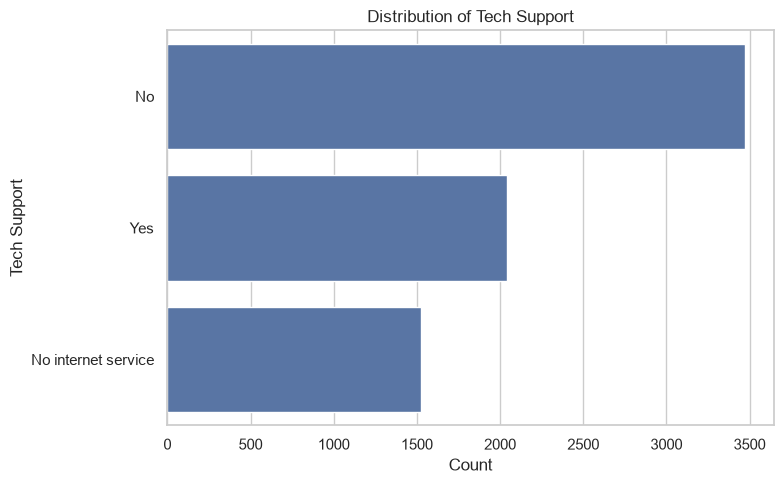

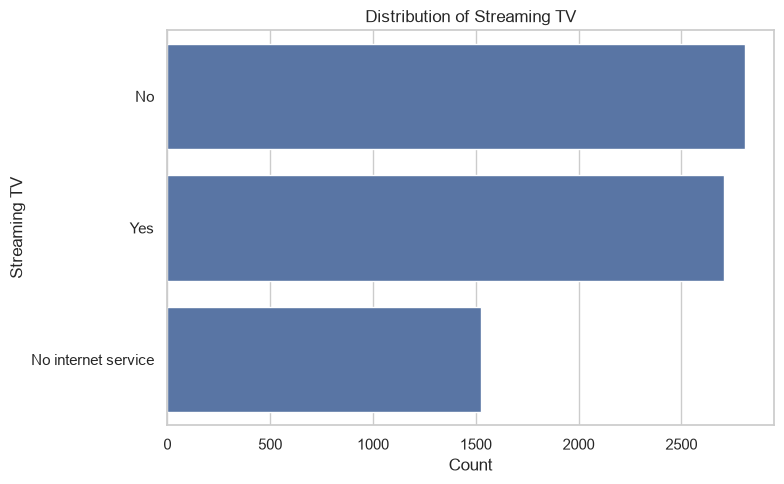

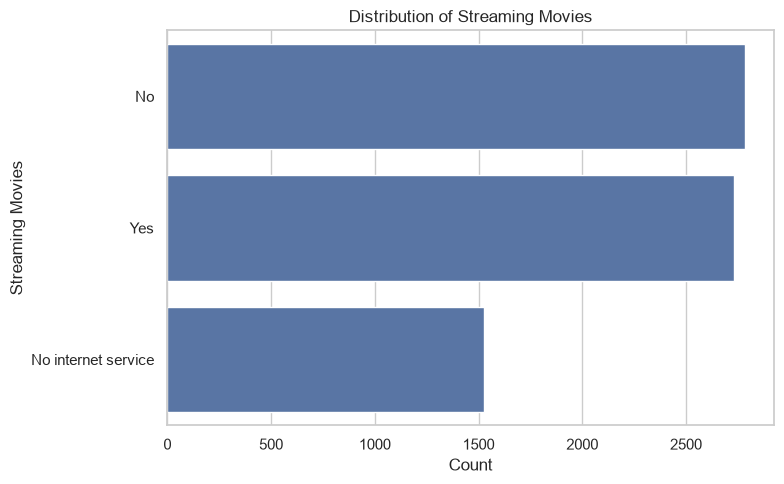

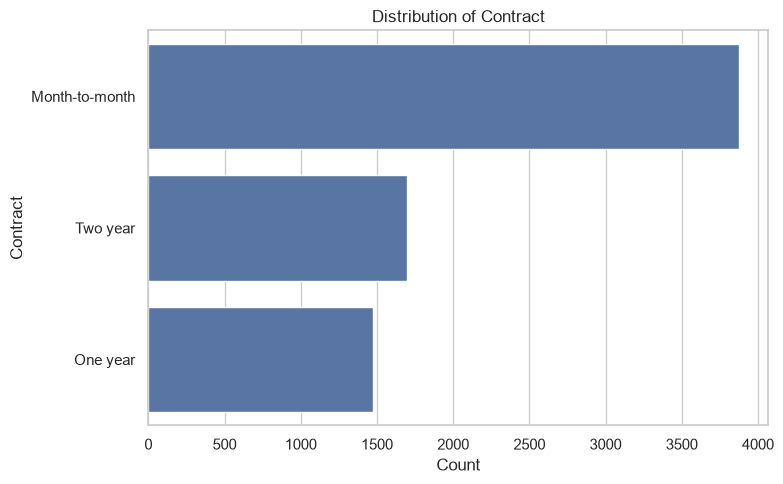

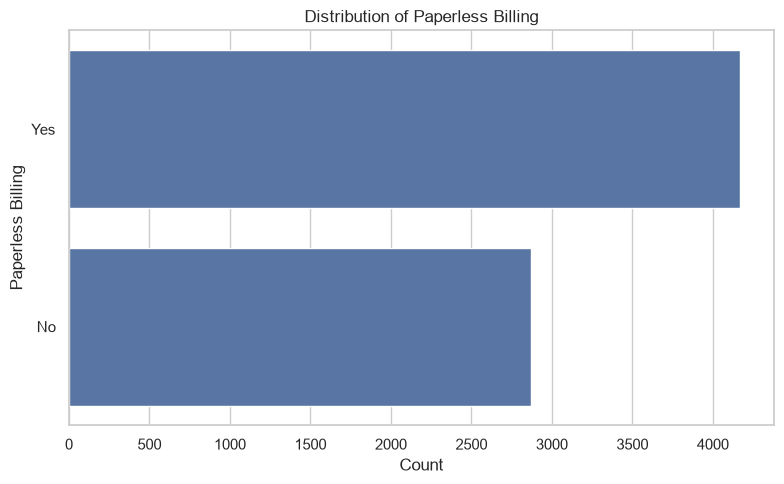

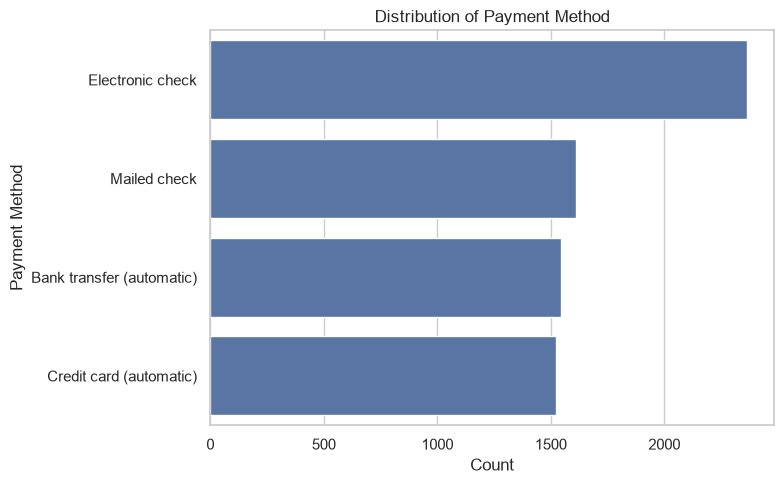

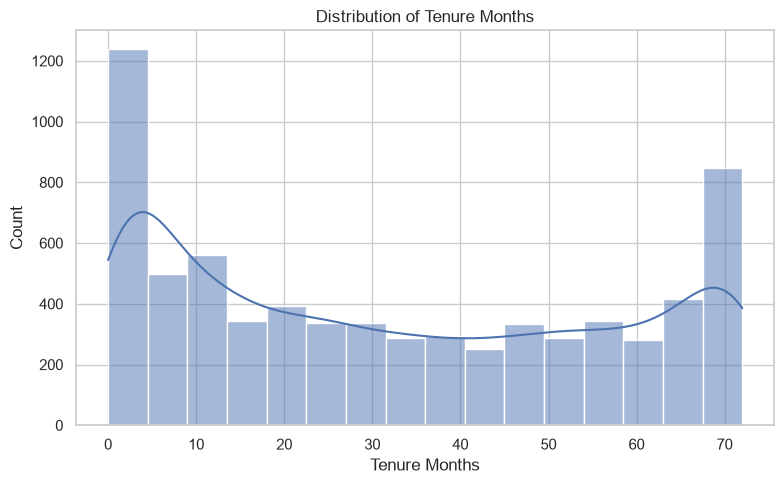

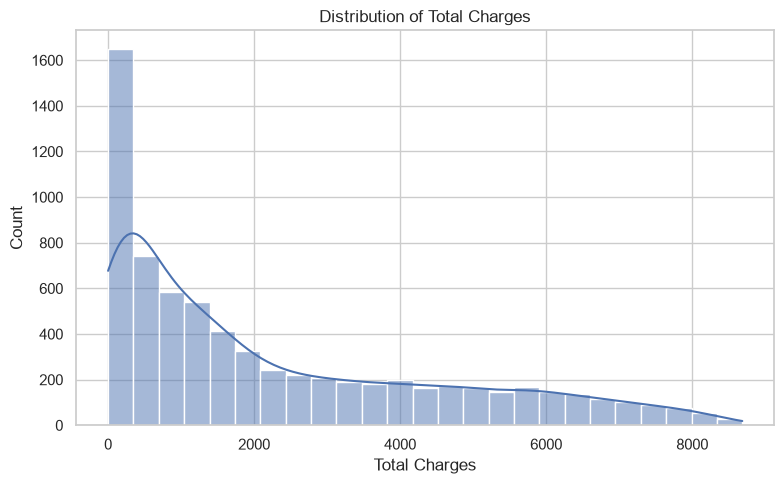

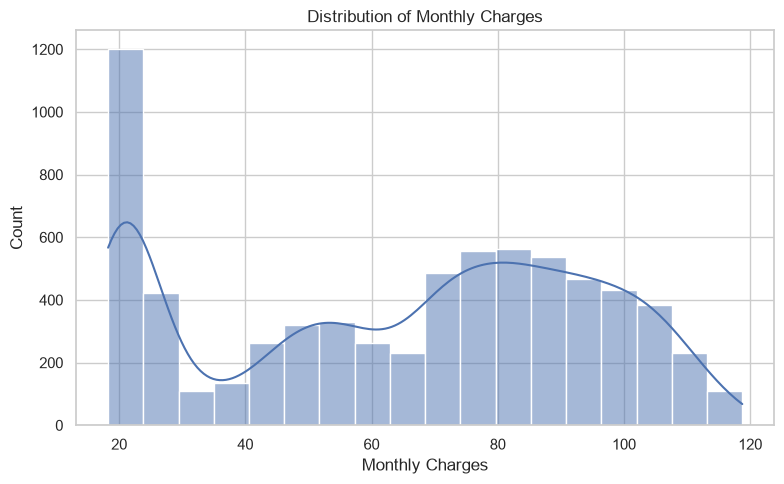

In [222]:
# Plot every column to view distributions
for col in df[categorical_cols + numeric_cols].columns:

    # Skip columns with no data
    if df[col].dropna().empty:
        continue

    plt.figure(figsize=(8, 5))

    # Numeric columns
    if pd.api.types.is_numeric_dtype(df[col]):
        sns.histplot(df[col].dropna(), kde=True)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')

    # Categorical columns
    else:
        # Get category counts
        counts = df[col].fillna('Missing').value_counts()

        # Limit extremely high-cardinality variables
        if len(counts) > 20:
            counts = counts.head(20)
            title = f'Top 20 Categories of {col}'
        else:
            title = f'Distribution of {col}'

        sns.barplot(x=counts.values, y=counts.index)
        plt.title(title)
        plt.xlabel('Count')
        plt.ylabel(col)

    plt.tight_layout()
    plt.show()

# Churn Distributions Investigation

In [223]:
print(df['Churn Label'].value_counts())
print(f"\nPercentage of customers who churn: {100 * df['Churn Value'].mean():.2f}%")

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Percentage of customers who churn: 26.54%


## Customer Characteristics and Their Relation to Churn

In [224]:
city_churn = (
    df.groupby('City')
      .agg(
          Customers=('Churn Value', 'size'),
          Churn_Rate=('Churn Value', 'mean')
      )
)

city_churn['Churn_Rate'] = city_churn['Churn_Rate'] * 100

city_churn = city_churn.sort_values(
    'Churn_Rate',
    ascending=False
)

print(city_churn[city_churn['Customers'] > 20].head(40))

                Customers  Churn_Rate
City                                 
Santa Rosa             24      45.833
Modesto                28      42.857
Santa Barbara          28      35.714
San Diego             150      33.333
Glendale               40      32.500
Torrance               25      32.000
Pasadena               30      30.000
San Francisco         104      29.808
Los Angeles           305      29.508
San Bernardino         28      28.571
Berkeley               32      28.125
Stockton               44      27.273
San Jose              112      25.893
Fresno                 64      25.000
Santa Ana              24      25.000
Anaheim                28      25.000
Riverside              32      25.000
Long Beach             60      25.000
Oakland                52      25.000
Sacramento            108      24.074
Burbank                25      24.000
Inglewood              25      20.000
Santa Monica           25      20.000
Chula Vista            25      20.000
Irvine      

Only 27/1129 cities have more than 20 customers located in them. Because of this, cities will probably not be reliable for predicting churn as the number of customers will be too low to rely on.

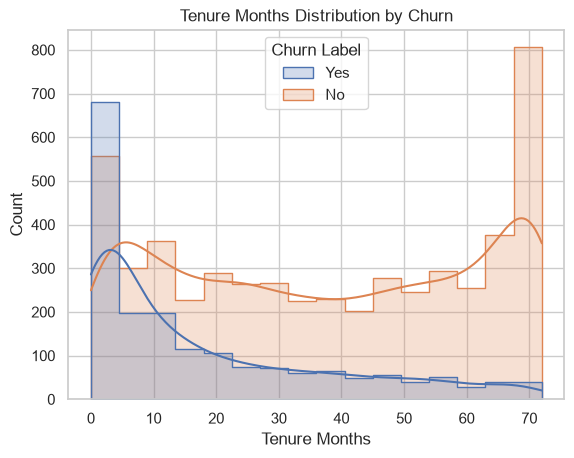

In [225]:
sns.histplot(data=df, x='Tenure Months', hue='Churn Label',
             kde=True, element='step')
plt.title('Tenure Months Distribution by Churn')
plt.show()

Lower tenure months have a much higher churn rate for lower months, and a much lower churn rate at higher months

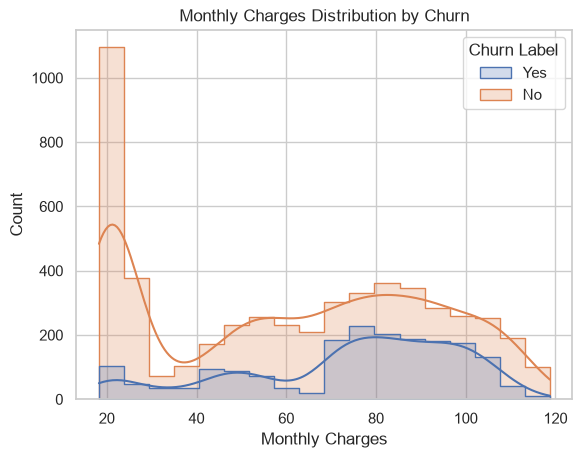

In [226]:
sns.histplot(data=df, x='Monthly Charges', hue='Churn Label',
             kde=True, element='step')
plt.title('Monthly Charges Distribution by Churn')
plt.show()

Lower costs tend to have a lower churn rate

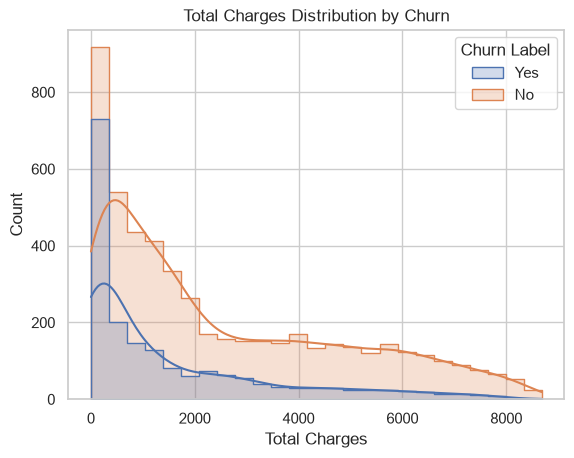

In [227]:
sns.histplot(data=df, x='Total Charges', hue='Churn Label',
             kde=True, element='step')
plt.title('Total Charges Distribution by Churn')
plt.show()

Higher total charges has a lower churn rate, most likely due to a customer having stayed for longer already, showing loyalty.

c:\Users\mlmug\miniconda3\envs\py313\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.


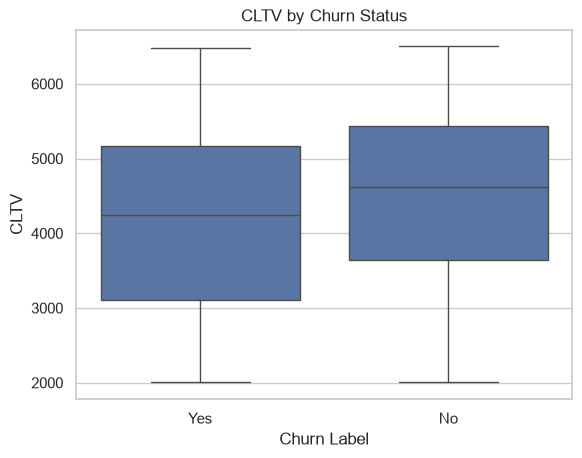

In [228]:
sns.boxplot(data=df, x='Churn Label', y='CLTV')
plt.title('CLTV by Churn Status')
plt.show()

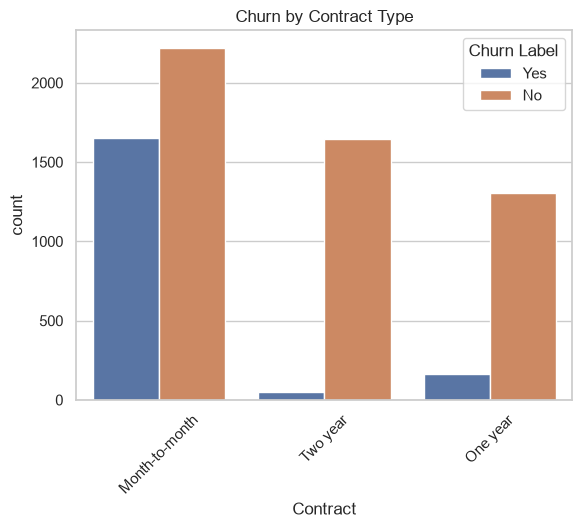

In [229]:
sns.countplot(data=df, x='Contract', hue='Churn Label')
plt.title('Churn by Contract Type')
plt.xticks(rotation=45)
plt.show()

Month-to-month contract type has a much higher churn rate.
- Month-to-month churn rate: 42.71%
- One year churn rate: 11.27%
- Two year churn rate: 2.83%

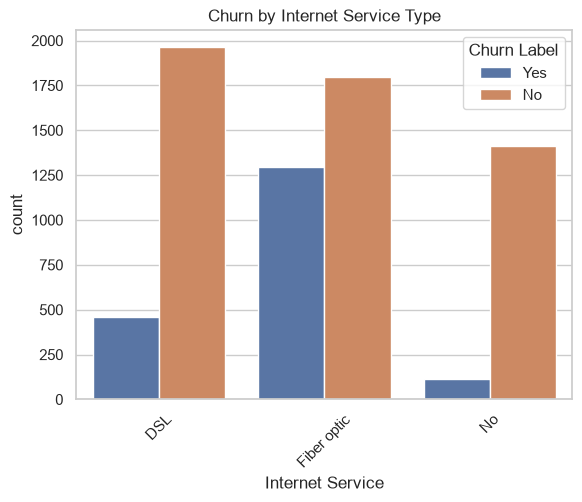

In [230]:
sns.countplot(data=df, x='Internet Service', hue='Churn Label')
plt.title('Churn by Internet Service Type')
plt.xticks(rotation=45)
plt.show()

Fiber optic internet service type has much higher churn rate
- DSL churn rate: 18.96%
- Fiber optic churn rate: 41.89%
- No internet churn rate: 7.40%

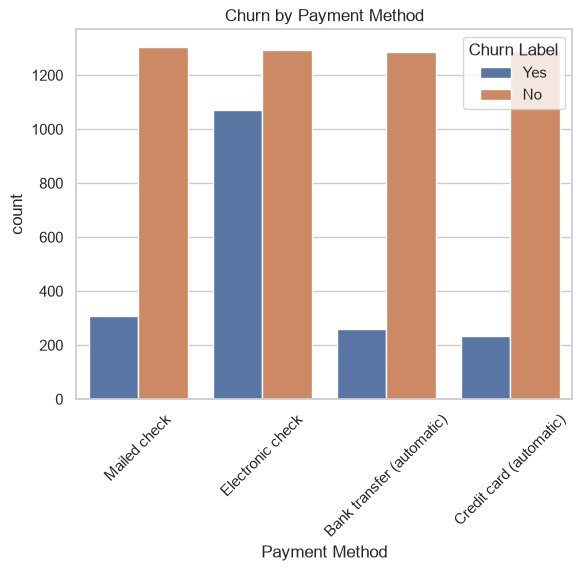

In [231]:
sns.countplot(data=df, x='Payment Method', hue='Churn Label')
plt.title('Churn by Payment Method')
plt.xticks(rotation=45)
plt.show()

Electronic check has higher churn rate
- Mailed check churn rate: 19.11%
- Electronic check churn rate: 45.29%
- Bank transfer churn rate: 16.71%
- Credit card churn rate: 15.24%

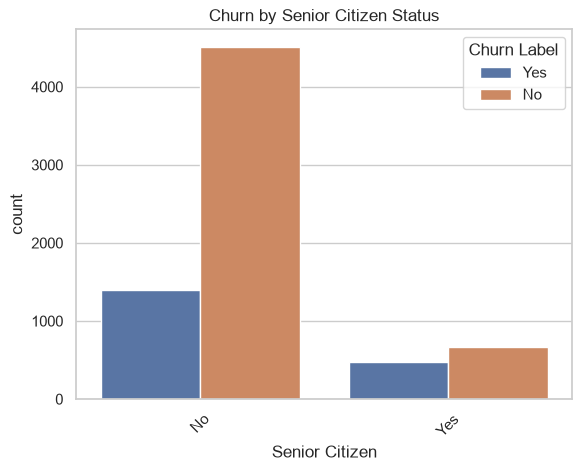

In [232]:
sns.countplot(data=df, x='Senior Citizen', hue='Churn Label')
plt.title('Churn by Senior Citizen Status')
plt.xticks(rotation=45)
plt.show()

Senior citizens have a higher churn rate
- Not senior citizen churn rate: 23.61%
- Senior citizen churn rate: 41.68%

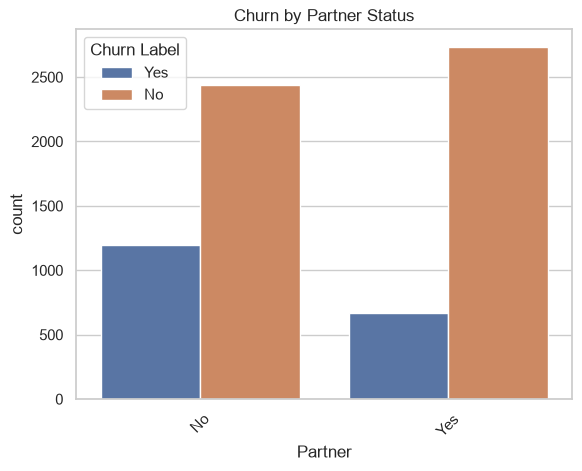

In [233]:
sns.countplot(data=df, x='Partner', hue='Churn Label')
plt.title('Churn by Partner Status')
plt.xticks(rotation=45)
plt.show()

Customers without partners have a higher churn rate
- No partner churn rate: 32.96%
- Has partner churn rate: 19.66%

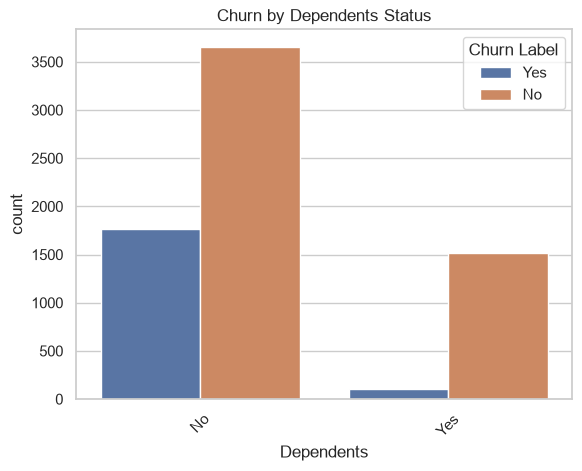

In [234]:
sns.countplot(data=df, x='Dependents', hue='Churn Label')
plt.title('Churn by Dependents Status')
plt.xticks(rotation=45)
plt.show()

Customers with no dependents have a higher churn rate than those who do.
- No dependents churn rate: 32.55%
- Has dependents churn rate: 6.52%

## Services and Their Relation to Churn

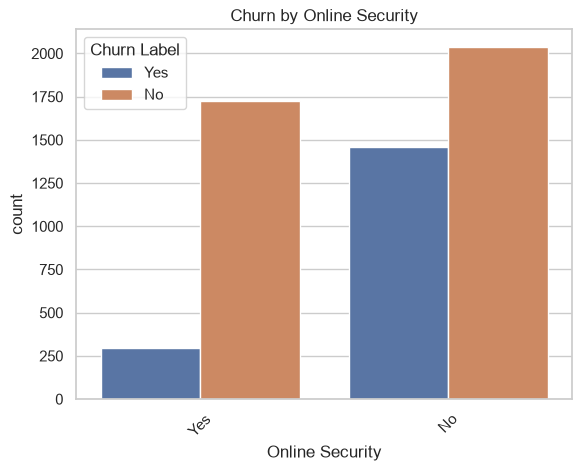

In [235]:
sns.countplot(data=df[df['Online Security'] != 'No internet service'], x='Online Security', hue='Churn Label')
plt.title('Churn by Online Security')
plt.xticks(rotation=45)
plt.show()

Customers with no online security have a higher churn rate than those who do.
- No online security churn rate: 41.77%
- Has online security churn rate: 14.61%

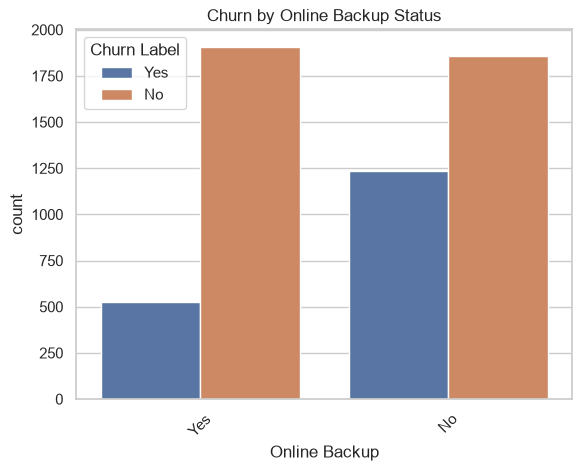

In [236]:
sns.countplot(data=df[df['Online Backup'] != 'No internet service'], x='Online Backup', hue='Churn Label')
plt.title('Churn by Online Backup Status')
plt.xticks(rotation=45)
plt.show()

Customers with no online backup have a higher churn rate.
- No online backup churn rate: 39.93%
- Has online backup churn rate: 21.53%

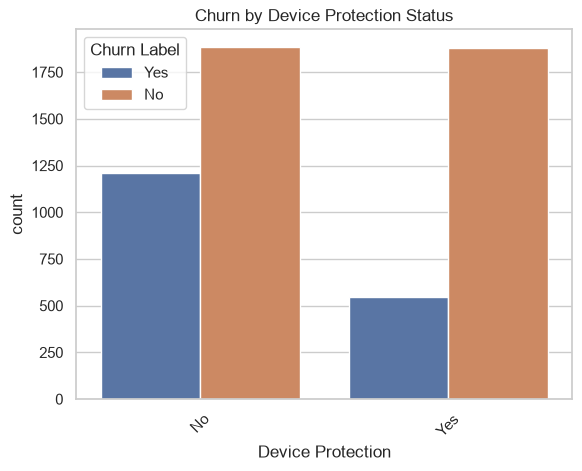

In [237]:
sns.countplot(data=df[df['Device Protection'] != 'No internet service'], x='Device Protection', hue='Churn Label')
plt.title('Churn by Device Protection Status')
plt.xticks(rotation=45)
plt.show()

Customers with no device protection have a higher churn rate.
- No device protection churn rate: 39.13%
- Has device protection churn rate: 22.50%

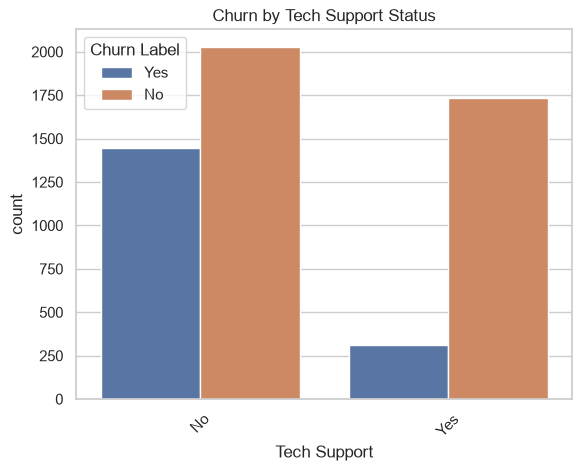

In [238]:
sns.countplot(data=df[df['Tech Support'] != 'No internet service'], x='Tech Support', hue='Churn Label')
plt.title('Churn by Tech Support Status')
plt.xticks(rotation=45)
plt.show()

Customers with no tech support have a higher churn rate.
- Has no tech support churn rate: 41.64%
- Has tech support churn rate: 15.17%

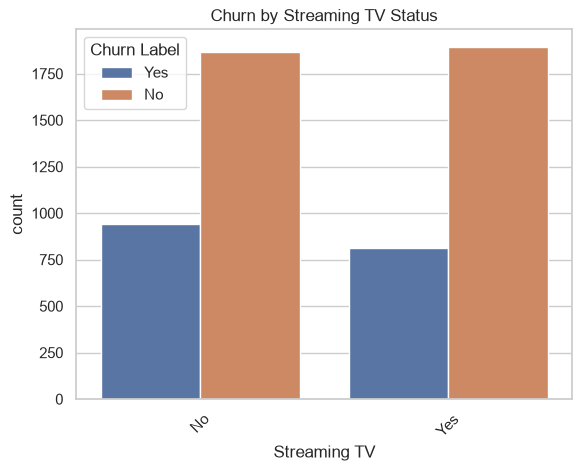

In [239]:
sns.countplot(data=df[df['Streaming TV'] != 'No internet service'], x='Streaming TV', hue='Churn Label')
plt.title('Churn by Streaming TV Status')
plt.xticks(rotation=45)
plt.show()

Streaming TV services doesn't differentiate churn rate by much.
- Streams TV churn rate: 30.07%
- Doesn't stream tv churn rate: 33.52%

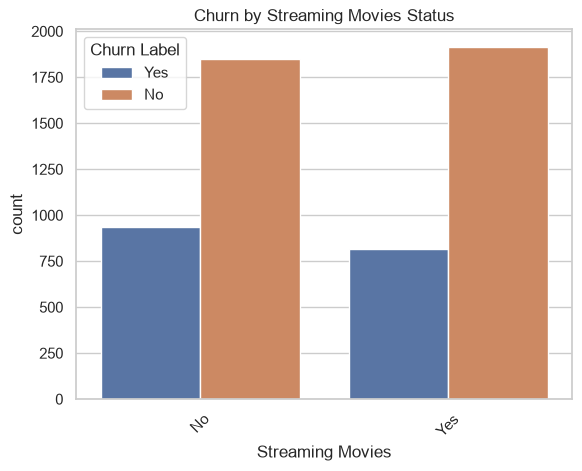

In [240]:
sns.countplot(data=df[df['Streaming Movies'] != 'No internet service'], x='Streaming Movies', hue='Churn Label')
plt.title('Churn by Streaming Movies Status')
plt.xticks(rotation=45)
plt.show()

Streaming movies services doesn't differentiate churn rate by much.
- Streams movies churn rate: 29.94%
- Doesn't stream movies churn rate: 33.68%

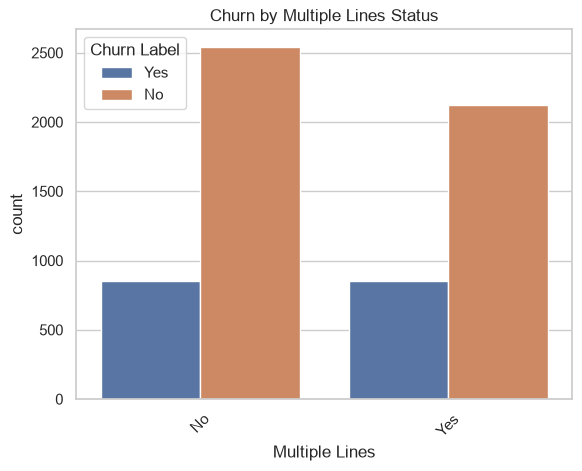

In [241]:
sns.countplot(data=df[df['Multiple Lines'] != 'No phone service'], x='Multiple Lines', hue='Churn Label')
plt.title('Churn by Multiple Lines Status')
plt.xticks(rotation=45)
plt.show()

Having multiple lines doesn't differentiate churn rate by much.
- Has multiple lines churn rate: 28.61%
- Doesn't have multiple lines churn rate: 25.04%

Across all services offerings, it appears that a lack of services, especially tech support, device protection, and online backup, result in a much higher churn rate.

## Categorical Features and Their Churn Rates Listed

In [242]:
for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(
        pd.crosstab(
            df[col],
            df['Churn Label'],
            normalize='index'
        ) * 100
    )


--- Gender ---
Churn Label     No    Yes
Gender                   
Female      73.079 26.921
Male        73.840 26.160

--- Senior Citizen ---
Churn Label        No    Yes
Senior Citizen              
No             76.394 23.606
Yes            58.319 41.681

--- Partner ---
Churn Label     No    Yes
Partner                  
No          67.042 32.958
Yes         80.335 19.665

--- Dependents ---
Churn Label     No    Yes
Dependents               
No          67.448 32.552
Yes         93.485  6.515

--- Phone Service ---
Churn Label       No    Yes
Phone Service              
No            75.073 24.927
Yes           73.290 26.710

--- Multiple Lines ---
Churn Label          No    Yes
Multiple Lines                
No               74.956 25.044
No phone service 75.073 24.927
Yes              71.390 28.610

--- Internet Service ---
Churn Label          No    Yes
Internet Service              
DSL              81.041 18.959
Fiber optic      58.107 41.893
No               92.595  7.405


## Numeric Features Correlation

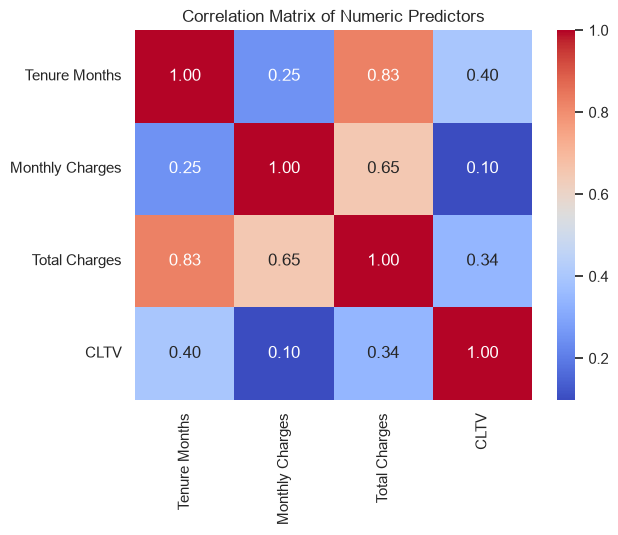

In [243]:
numeric_predictors = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

sns.heatmap(
    df[numeric_predictors].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix of Numeric Predictors')
plt.show()

Correlations between numeric features is only seen mostly between charges and tenure months.

Notable features for identifying churn rate:
- Tenure months
- Monthly charges
- Total charges
- Contract Type
- Internet Service type
- Payment Method
- Senior Citizen
- Dependents
- Online Security
- Online Backup
- Device Protection
- Tech Support

# Training and Testing Data

Explanation for columns being dropped:
- Lat Long: Combines data from longitude and latitude
- Longitude: Customers are concetrated in California, latitude and longitude aren't important to churn after eda investigation
- Latitude: Same as Longitude
- CustomerID: Just a method to identify customers, not neded to predict churn
- Country: All customers are domestic
- Churn Label: This is the class, not needed for prediction
- Count: Count of customers not needed
- Churn Score: This score was made using an IBM prediction system, results in data leakage, removed
- Churn Reason: Data leakage, as only customers who have churned have a churn reason
- CLTV: Customer lifetime value. This feature is good for deciding what customers to prioritize, but not needed to predict churn
- City: Lots of cities have below 20 customers, these low numbers make cities an unreliable metric for predicting churn.
- Zip code: Same case but more extreme as city

In [244]:
drop_cols = ['CustomerID', 'Country', 'Lat Long', 'Churn Label', 'Churn Value', 'Count',
             'Churn Score', 'Churn Reason', 'CLTV', 'State', 'City', 'Zip Code', 'Latitude', 'Longitude']

X = df.drop(columns=drop_cols)
y = df['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

# Predictive Modeling and Interpretation

This section extends the existing analysis into predictive modeling. The goal is to predict whether a customer will churn and compare three classification approaches using the customer information retained after the exploratory analysis. The emphasis is on the predictive accuracy of the models for previously unseen customers rather than on fitting the existing data as well as possible. Logistic regression, k-nearest neighbors and random forest models are three different approaches to the binary classification to compare.


In [245]:
numeric_features = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric_features),
    ("categorical",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical_features)
])

print("Numeric predictors:",numeric_features)
print("Categorical predictors:",categorical_features)


Numeric predictors: ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical predictors: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


C:\Users\mlmug\AppData\Local\Temp\ipykernel_40784\1123419397.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.


## Baseline Model



In [246]:
baseline_model = DummyClassifier(strategy="most_frequent",random_state=1)

baseline_model.fit(X_train, y_train)
baseline_prediction = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test,baseline_prediction)

print(f"Baseline validation accuracy: {baseline_accuracy:.3f}")


Baseline validation accuracy: 0.735


## Logistic Regression

Logistic regression is a simple classification model and provides a baseline for comparing the other models. Because churn is imbalanced, class weights are used to give more importance to the churn class. The regularization parameter C is tuned using five-fold cross-validation with ROC AUC as the scoring metric.


In [247]:
logistic_pipeline = Pipeline([("preprocessor",preprocessor),("model",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=1))])

logistic_grid = GridSearchCV(logistic_pipeline,param_grid={"model__C":[0.1,1,10]},scoring="roc_auc",cv=5,n_jobs=-1)
logistic_grid.fit(X_train,y_train)

logistic_validation_probability = logistic_grid.predict_proba(X_test)[:,1]
logistic_validation_prediction = (logistic_validation_probability >= 0.50).astype(int)

print("Best logistic regression parameters:")
print(logistic_grid.best_params_)


Best logistic regression parameters:
{'model__C': 1}


### Validation Results


In [248]:
logistic_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                                 "Validation":[accuracy_score(y_test,logistic_validation_prediction),
                                               precision_score(y_test,logistic_validation_prediction),
                                               recall_score(y_test,logistic_validation_prediction),
                                               f1_score(y_test,logistic_validation_prediction),
                                               roc_auc_score(y_test,logistic_validation_probability)]})

display(logistic_results)

,Metric,Validation
0,Accuracy,0.760
1,Precision,0.531
2,Recall,0.807
3,F1,0.641
4,ROC AUC,0.853


The logistic regression model had a validation ROC AUC of around 0.853. This means that the model was generally able to distinguish between customers that churned and those that did not. Its recall was around 80.7%, which means the model was able to find most of the actual churn cases in the validation data. But the accuracy of it was about 76.0%, so there were still a fair number of incorrect classifications. The results suggest the logistic regression was particularly useful to identify potential churners but have to compare the performance with other models to select the final model.


## k-Nearest Neighbors

k-NN classifies a customer using the outcomes of nearby observations in predictor space. The number of neighbors and weighting method are tuned using five-fold cross-validation. A small set of candidate values is used to keep the analysis straightforward while still testing whether the neighborhood size affects predictive performance.


In [249]:
knn_pipeline = Pipeline([("preprocessor",preprocessor),("model",KNeighborsClassifier())])

knn_grid = GridSearchCV(knn_pipeline,param_grid={"model__n_neighbors":[5,15,25],"model__weights":["uniform","distance"]},scoring="roc_auc",cv=5,n_jobs=-1)
knn_grid.fit(X_train,y_train)

knn_validation_probability = knn_grid.predict_proba(X_test)[:,1]
knn_validation_prediction = (knn_validation_probability >= 0.50).astype(int)

print("Best k-NN parameters:")
print(knn_grid.best_params_)

Best k-NN parameters:
{'model__n_neighbors': 25, 'model__weights': 'uniform'}


### Validation Results


In [250]:
knn_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                            "Validation":[accuracy_score(y_test,knn_validation_prediction),
                                          precision_score(y_test,knn_validation_prediction),
                                          recall_score(y_test,knn_validation_prediction),
                                          f1_score(y_test,knn_validation_prediction),
                                          roc_auc_score(y_test,knn_validation_probability)]})

display(knn_results)


,Metric,Validation
0,Accuracy,0.798
1,Precision,0.627
2,Recall,0.587
3,F1,0.606
4,ROC AUC,0.838


### Interpretation

k-NN provides a different approach by classifying customers based on similarity to other customers. In this dataset, the model achieved a validation ROC AUC of about 0.838 and recall of about 58.6%, meaning it identified fewer actual churners than logistic regression. The model also requires both numeric variables to be standardized and categorical variables to be one-hot encoded, which is especially important here because the dataset contains many categorical customer and service variables.


## Random Forest

Random forest is included as exploratory analysis because churn may depend on combinations of contract type, tenure, charges and service characteristics. These relationships may not be well described by a single linear boundary. The model is tuned on a small grid of tree depth and minimum leaf size with number of trees fixed at 200.


In [251]:
random_forest_pipeline = Pipeline([("preprocessor",preprocessor),("model",RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=1,n_jobs=-1))])

random_forest_grid = GridSearchCV(random_forest_pipeline,param_grid={"model__max_depth":[5,10,None],"model__min_samples_leaf":[1,5]},scoring="roc_auc",cv=5,n_jobs=-1)
random_forest_grid.fit(X_train,y_train)

rf_validation_probability = random_forest_grid.predict_proba(X_test)[:,1]
rf_validation_prediction = (rf_validation_probability >= 0.50).astype(int)

print("Best random forest parameters:")
print(random_forest_grid.best_params_)

Best random forest parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 5}


### Validation Results


In [252]:
rf_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                           "Validation":[accuracy_score(y_test,rf_validation_prediction),
                                         precision_score(y_test,rf_validation_prediction),
                                         recall_score(y_test,rf_validation_prediction),
                                         f1_score(y_test,rf_validation_prediction),
                                         roc_auc_score(y_test,rf_validation_probability)]})

display(rf_results)


,Metric,Validation
0,Accuracy,0.761
1,Precision,0.534
2,Recall,0.799
3,F1,0.640
4,ROC AUC,0.856


The random forest performed well on the validation data, with a ROC AUC of about 0.855, recall of about 77.5%, and F1 score of about 64.5%. This means it was able to identify a large portion of the customers who actually churned while maintaining a similar overall performance to logistic regression.


## Compare Models

The models are compared using the same validation data. ROC AUC is the primary comparison measure. F1, recall, precision, and accuracy are also reported to show the trade-offs at the 0.50 classification cutoff.


In [253]:
model_comparison = pd.DataFrame({
    "Model":["Logistic Regression","k-NN","Random Forest"],
    "Accuracy":[accuracy_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "Precision":[precision_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "Recall":[recall_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "F1":[f1_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "ROC AUC":[roc_auc_score(y_test,p) for p in [logistic_validation_probability,knn_validation_probability,rf_validation_probability]]
})

display(model_comparison.sort_values("ROC AUC",ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest,0.761,0.534,0.799,0.640,0.856
1,Logistic Regression,0.760,0.531,0.807,0.641,0.853
2,k-NN,0.798,0.627,0.587,0.606,0.838


Logistic regression had the highest recall at about 80.7%, while k-NN had the lowest recall at about 58.6% and a ROC AUC of about 0.838. Random forest had the highest ROC AUC at about 0.855, with a recall of about 77.5% and an F1 score of about 64.5%. Based on these results, random forest was selected because it provided the strongest overall ability to distinguish between customers who churned and those who did not. This decision is based on the validation performance of the models, and the variables identified by the model should be viewed as useful predictors.


In [254]:
selected_model_name = "Random Forest"
selected_model = random_forest_grid.best_estimator_

print(f"Selected model: {selected_model_name}")
print(f"Best parameters: {random_forest_grid.best_params_}")


Selected model: Random Forest
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5}


# Business Applications

The purpose of this portion of the project is to take the interpretation a step further to identify customer types that are more or less likely to churn.

In [255]:
# creating a data frame (df2) with the predicted churn probabilities and predicted churn result

df2 = df.copy()

drop_cols2 = ['CustomerID', 'Country', 'Lat Long', 'Churn Label', 'Count', 'State', 'City', 'Zip Code', 'Latitude', 'Longitude']

df2 = df.drop(columns=drop_cols2)

X2 = df2.drop(columns = ["Churn Value", "Churn Score", "CLTV", "Churn Reason"])

rf_prob = random_forest_grid.predict_proba(X2)[:,1]
rf_pred = (rf_prob >= 0.50).astype(int)

df2["rf_prob"] = rf_prob
df2["rf_pred"] = rf_pred

pd.set_option('display.max_columns', None)
df2.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,rf_prob,rf_pred
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,86,3239,Competitor made better offer,0.635,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1,67,2701,Moved,0.824,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500,1,86,5372,Moved,0.701,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050,1,84,5003,Moved,0.421,0
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300,1,89,5340,Competitor had better devices,0.480,0


In [256]:
# # look at the column distributions across the actual churn and predicted churn groups

# cat_cols = ["Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Multiple Lines", "Internet Service", 
# "Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies", "Contract", 
# "Paperless Billing", "Payment Method"]

# num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

# actual_churn = "Churn Value"
# pred_churn = "rf_pred"

# # helper function: count and percentage of response values
# def response_summary(data, response_col, prefix):
#     counts = data[response_col].value_counts()

#     n = data[response_col].notna().sum()

#     result = {}
#     for value in [0, 1]:
#         count = counts.get(value, 0)
#         result[f"{prefix}_{value}_count"] = count
#         result[f"{prefix}_{value}_pct"] = (
#             round(count / n * 100, 1) if n else 0
#         )

#     return result

In [257]:
# # look at the categorical column distributions across the actual churn and predicted churn groups 

# # take out

# categorical_rows = []

# for col in cat_cols:
#     if col not in df2.columns:
#         continue

#     for category, group in df2.groupby(
#         col, dropna=False, observed=True
#     ):
#         n = len(group)

#         actual_count = (group[actual_churn] == 1).sum()
#         predicted_count = (group[pred_churn] == 1).sum()

#         categorical_rows.append({
#             "Variable": col,
#             "Category": str(category),
#             "Count": n,
#             "Percentage": round(n / len(df2) * 100, 1)
#                 if len(df2) else 0,
#             "Actual Churn Count": actual_count,
#             "Actual Churn % of Group": round(
#                 actual_count / n * 100, 1
#             ) if n else 0,

#         })

# categorical_table = pd.DataFrame(categorical_rows)

# categorical_table = categorical_table.sort_values(
#     by="Actual Churn % of Group",
#     ascending=False
# ).reset_index(drop=True)

# display(categorical_table)

# # Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

When breaking the categorical columns into their categories, or groups, the proportion of churners can help to start build a profile of customers based on churn. For example, of those who pay by electronic check, 45.3% of them have churned, where as those who pay automatically via credit card, 15.2% of them have churned. Ultimately, this table identifies categories or groups with high (and low) churn rates, and could be used to build an image of high and low risk churn customers.

In [258]:
# comparing proportions of actual and predicted churners against the entire dataset

total_n = len(df2)

categorical_rows2 = []

for col in cat_cols:
    if col not in df2.columns:
        continue

    for category, group in df2.groupby(
        col, dropna=False, observed=True
    ):
        n = len(group)

        actual_count = (group[actual_churn] == 1).sum()
        predicted_count = (group[pred_churn] == 1).sum()

        categorical_rows2.append({
            "Variable": col,
            "Category": str(category),

            # Category prevalence in the entire dataset
            "Category Count": n,
            "Category % of Dataset": round(
                n / total_n * 100, 1
            ) if total_n else 0,

            # Actual churn prevalence
            "Actual Churn Count": actual_count,
            "Actual Churn Rate of Group (%)": round(
                actual_count / n * 100, 1
            ) if n else 0,
            "Actual Churn Rate of Dataset (%)": round(
                actual_count / total_n * 100, 1
            ) if total_n else 0,

            # Predicted churn prevalence
            "Predicted Churn Count": predicted_count,
            "Predicted Churn Rate of Group (%)": round(
                predicted_count / n * 100, 1
            ) if n else 0,
            "Predicted Churn Rate of Dataset (%)": round(
                predicted_count / total_n * 100, 1
            ) if total_n else 0
        })

categorical_table2 = pd.DataFrame(categorical_rows2)

categorical_table2 = categorical_table2.sort_values(
    by="Actual Churn Count",
    ascending=False
).reset_index(drop=True)

display(
    categorical_table2.style.format({
        "Category % of Dataset": "{:.1f}",
        "Actual Churn Rate of Group (%)": "{:.1f}",
        "Actual Churn Rate of Dataset (%)": "{:.1f}",
        "Predicted Churn Rate of Group (%)": "{:.1f}",
        "Predicted Churn Rate of Dataset (%)": "{:.1f}"
    })
)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Variable,Category,Category Count,Category % of Dataset,Actual Churn Count,Actual Churn Rate of Group (%),Actual Churn Rate of Dataset (%),Predicted Churn Count,Predicted Churn Rate of Group (%),Predicted Churn Rate of Dataset (%)
0,Dependents,No,5416,76.9,1763,32.6,25.0,2667,49.2,37.9
1,Phone Service,Yes,6361,90.3,1699,26.7,24.1,2564,40.3,36.4
2,Contract,Month-to-month,3875,55.0,1655,42.7,23.5,2624,67.7,37.3
3,Online Security,No,3498,49.7,1461,41.8,20.7,2277,65.1,32.3
4,Tech Support,No,3473,49.3,1446,41.6,20.5,2246,64.7,31.9
5,Paperless Billing,Yes,4171,59.2,1400,33.6,19.9,2065,49.5,29.3
6,Senior Citizen,No,5901,83.8,1393,23.6,19.8,2063,35.0,29.3
7,Internet Service,Fiber optic,3096,44.0,1297,41.9,18.4,2024,65.4,28.7
8,Online Backup,No,3088,43.8,1233,39.9,17.5,1941,62.9,27.6
9,Device Protection,No,3095,43.9,1211,39.1,17.2,1899,61.4,27.0


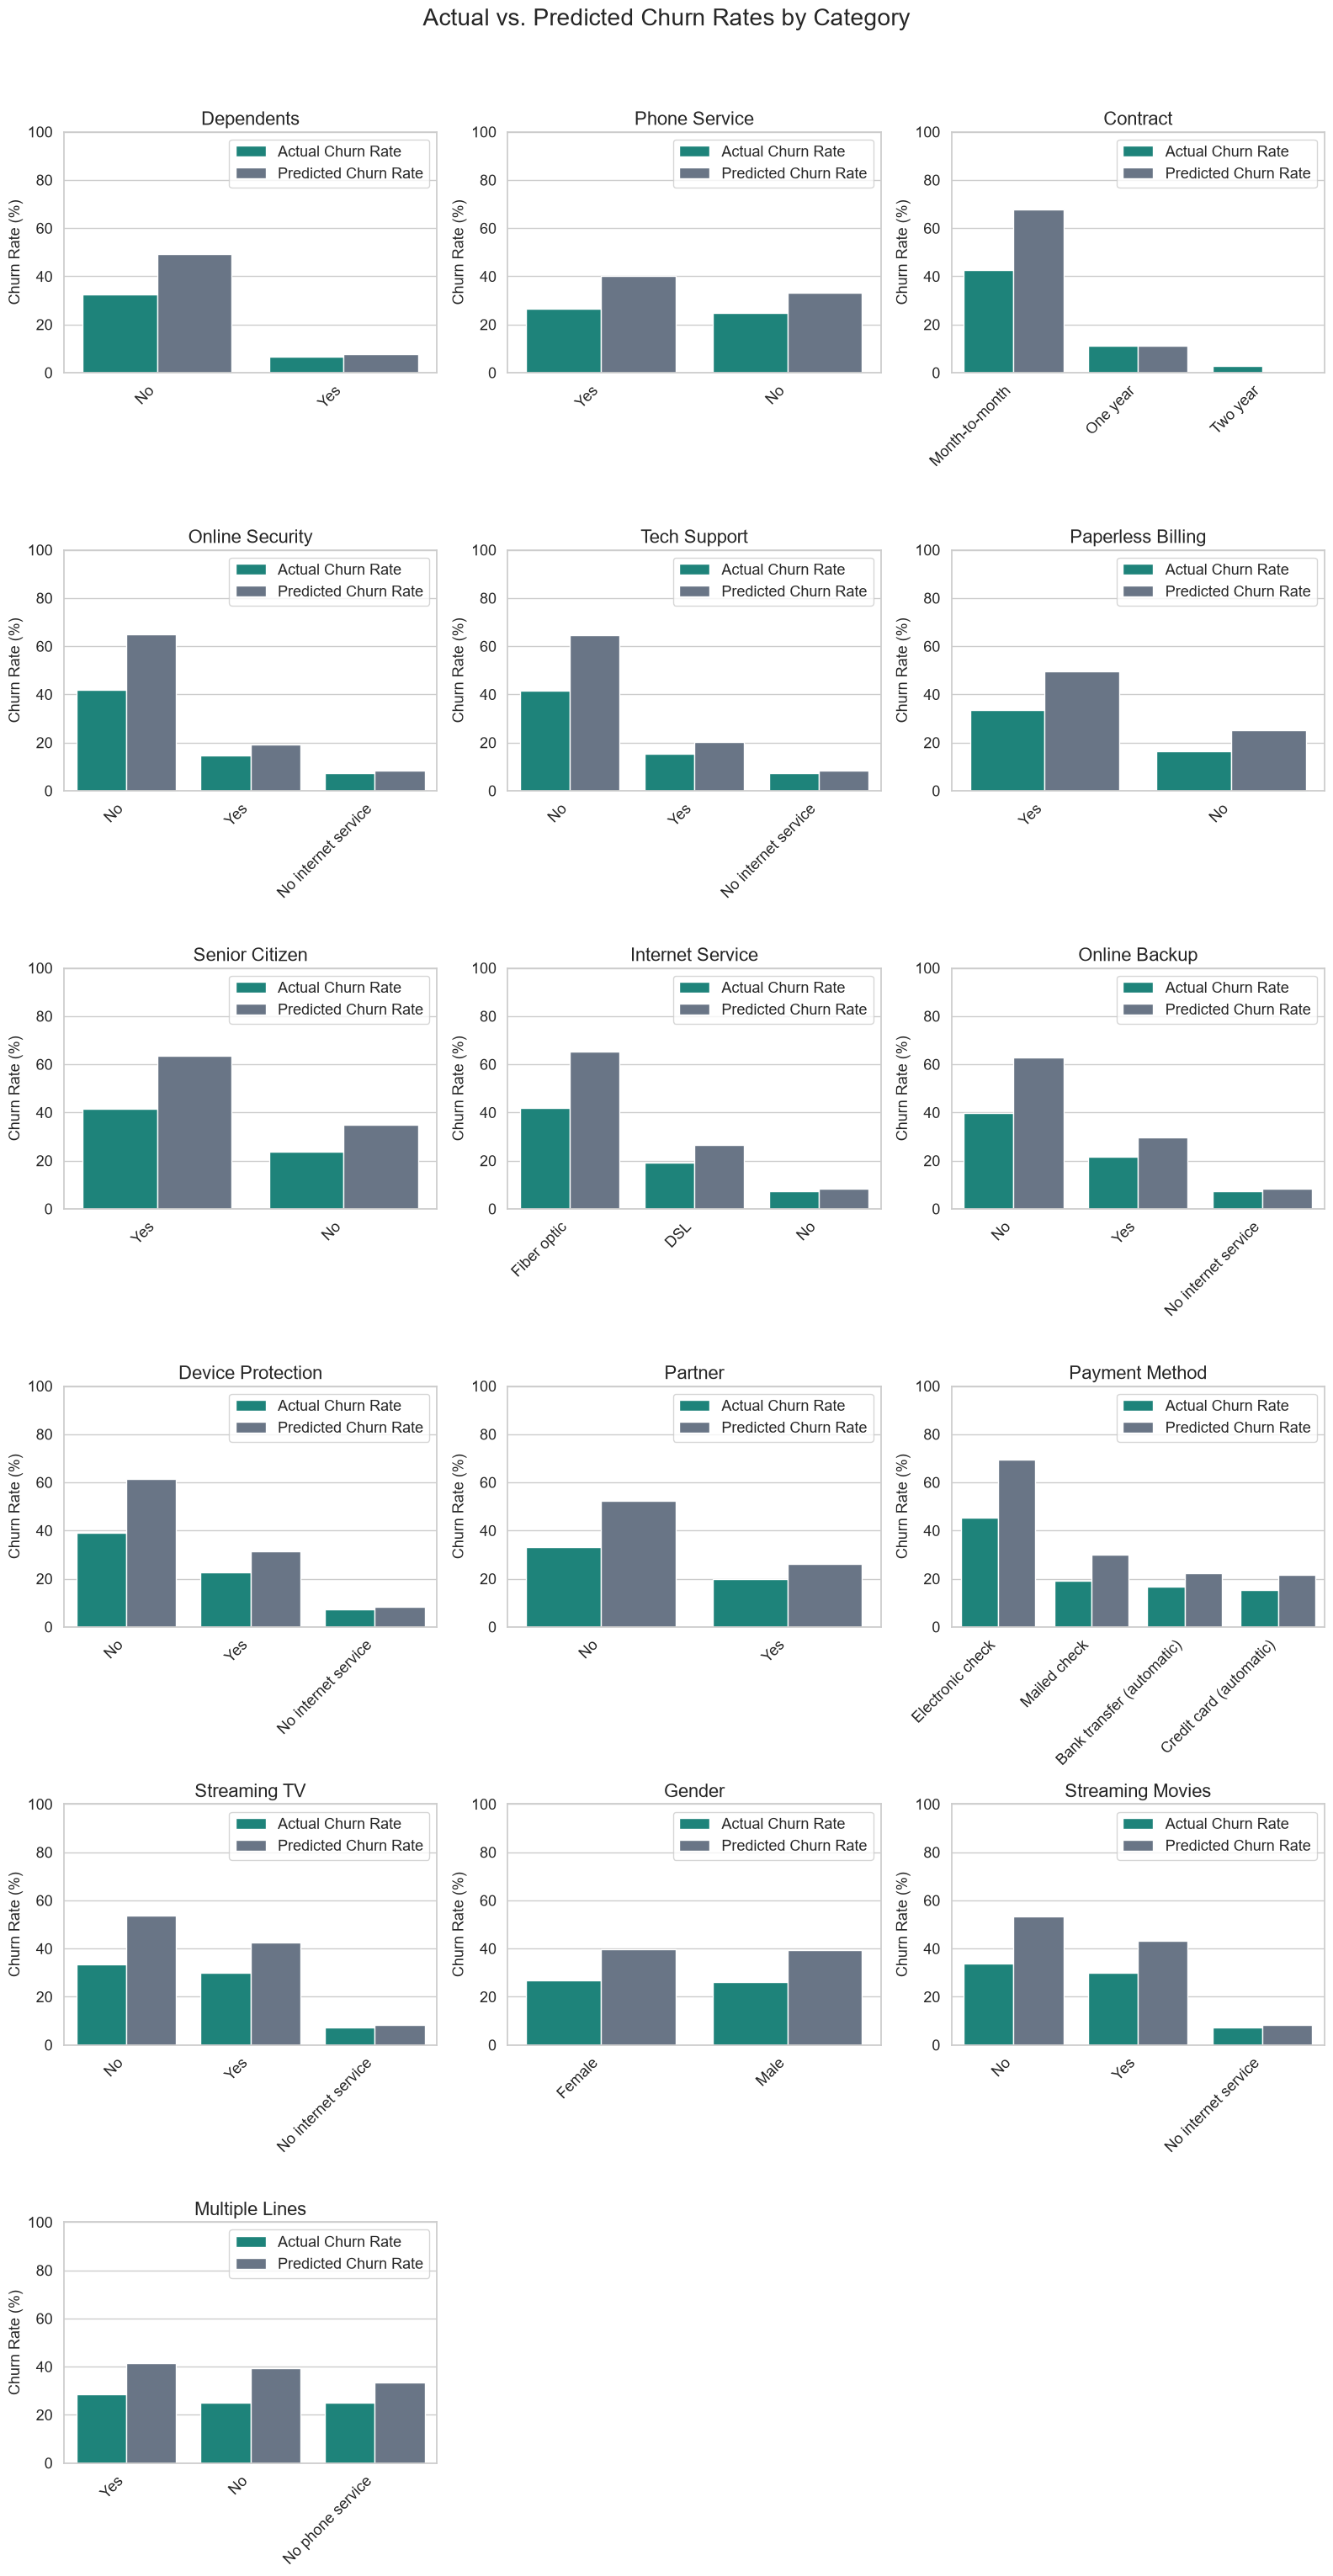

In [259]:
# visualize differences in actual and predicted in-group churn rates for each category

sns.set_theme(style = "whitegrid")

# Column names
variable_col = "Variable"
category_col = "Category"
actual_col = "Actual Churn Rate of Group (%)"
predicted_col = "Predicted Churn Rate of Group (%)"

# Identify variables to plot
variables = categorical_table2[variable_col].unique()

# Matrix layout
n_cols = 3
n_rows = (len(variables) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize = (16, 5 * n_rows),
    squeeze = False
)

axes = axes.flatten()

for i, variable in enumerate(variables):
    ax = axes[i]

    plot_data = categorical_table2[
        categorical_table2[variable_col] == variable
    ].copy()

    # Sort categories by actual churn rate
    plot_data = plot_data.sort_values(
        by = actual_col,
        ascending = False
    )

    # Reshape data for grouped bars
    plot_data = plot_data.melt(
        id_vars = [category_col],
        value_vars = [actual_col, predicted_col],
        var_name = "Churn Type",
        value_name = "Churn Rate (%)"
    )

    plot_data["Churn Type"] = plot_data["Churn Type"].map({
        actual_col: "Actual Churn Rate",
        predicted_col: "Predicted Churn Rate"
    })

    sns.barplot(
        data=plot_data,
        x = category_col,
        y = "Churn Rate (%)",
        hue = "Churn Type",
        hue_order = ["Actual Churn Rate", "Predicted Churn Rate"],
        palette = palette,
        ax = ax
    )

    ax.set_title(f"{variable}", fontsize = 16)
    ax.set_xlabel("", fontsize = 13)
    ax.set_ylabel("Churn Rate (%)", fontsize = 13)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize = 13, rotation = 45)
    ax.tick_params(axis="y", labelsize = 13)
    ax.legend(title="", fontsize=13)

    # Align category labels
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Remove unused subplots
for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Actual vs. Predicted Churn Rates by Category",
    fontsize=20,
    y=1.02
)

plt.tight_layout()
plt.show()

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

This table accomplishes two things. First, it allows for a direct comparison of the actual churn counts and percentages (against the entire dataset) with that of the random forests-generated predictions. The model appears to overpredict churn, particularly at the higher churn percentages. For example, 1763 customers without dependents churned (25.0%), but the model predicted 2667 customers (37.9%). Second, this table shows, when looking at all churners, how much each category or group contributes to churn. Customers without dependents contribute to 25.0% of overall churn.

In [260]:
# describe the numerical columns

df2[["Tenure Months", "Monthly Charges", "Total Charges"]].describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000,7043.000,7043.000
mean,32.371,64.762,2279.734
std,24.559,30.090,2266.794
min,0.000,18.250,0.000
25%,9.000,35.500,398.550
50%,29.000,70.350,1394.550
75%,55.000,89.850,3786.600
max,72.000,118.750,8684.800


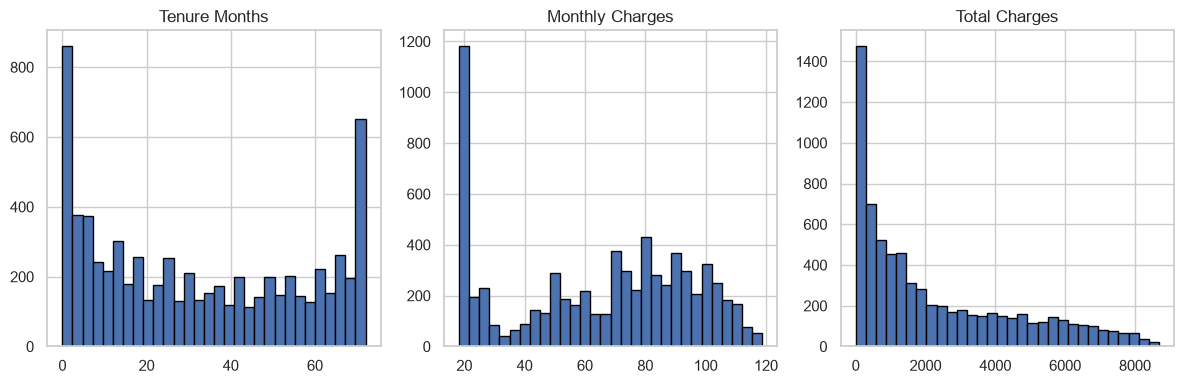

In [261]:
# visualizing distribution of numerical columns

df2[["Tenure Months", "Monthly Charges", "Total Charges"]].hist(
    figsize=(12, 4),
    bins=30,
    layout=(1, 3),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [262]:
# # look at the numerical column distributions across the actual churn and predicted churn groups
# # based on the distribution of the data, as visualized by the histograms, 
# # bins of equal size were chosen so that the bins have equal weights and there is no specific need for evenly spaced bins

# group_rows_num = []

# for col in num_cols:
#     # Convert to numeric and exclude missing values for bin creation
#     values = pd.to_numeric(df2[col], errors="coerce")

#     # Create up to 4 quantile-based groups
#     try:
#         bins = pd.qcut(
#             values,
#             q=4,
#             duplicates="drop"
#         )
#     except ValueError:
#         print(f"Skipping {col}: unable to create groups.")
#         continue

#     temp = df2.copy()
#     temp["_range"] = bins

#     for category, group in temp.groupby(
#         "_range", observed=True
#     ):
#         n = len(group)

#         actual_count = (group[actual_churn] == 1).sum()
#         predicted_count = (group[pred_churn] == 1).sum()

#         group_rows_num.append({
#             "Variable": col,
#             "Range": str(category),
#             "Group Size": n,
#             "Percentage": round(n / len(df2) * 100, 1)
#                 if len(df2) else 0,
#             "Actual Churn Count": actual_count,
#             "Actual Churn % of Group": round(
#                 actual_count / n * 100, 1
#             ) if n else 0
#         })

# numerical_group_table = pd.DataFrame(group_rows_num)

# numerical_group_table = numerical_group_table.sort_values(
#     ["Actual Churn % of Group"],
#     ascending=[False]
# ).reset_index(drop=True)

# display(numerical_group_table)

# # Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

When dividing the columns into bins, the proportion of churners can help to start build a profile of customers based on churn. For example, of customers with tenures of 9 months or less, 49.8% of them have churned, where as those with tenures of 55-72 months, 7.7% of them have churned. Ultimately, this table identifies categories or groups with high (and low) churn rates, and could be used to build an image of high and low risk churn customers.

In [263]:
# comparing proportions of actual and predicted churners against the entire dataset

group_rows_num = []

for col in num_cols:
    # Convert to numeric and exclude missing values for bin creation
    values = pd.to_numeric(df2[col], errors="coerce")

    # Create up to 4 quantile-based groups
    try:
        bins = pd.qcut(
            values,
            q=4,
            duplicates="drop"
        )
    except ValueError:
        print(f"Skipping {col}: unable to create groups.")
        continue

    temp = df2.copy()
    temp["_range"] = bins

    for category, group in temp.groupby(
        "_range", observed=True
    ):
        n = len(group)
        total_n = len(df2)

        actual_count = (group[actual_churn] == 1).sum()
        predicted_count = (group[pred_churn] == 1).sum()

        group_rows_num.append({
            "Variable": col,
            "Range": str(category),
            "Group Size": n,
            "Category % of Dataset": round(
                n / total_n * 100, 1
            ) if total_n else 0,
            "Actual Churn Count": actual_count,
            "Actual Churn Rate of Group (%)": round(
                actual_count / n * 100, 1
            ) if n else 0,
            "Actual Churn Rate of Dataset (%)": round(
                actual_count / total_n * 100, 1
            ) if n else 0,
            "Predicted Churn Count": predicted_count,
            "Predicted Churn Rate of Group (%)": round(
                predicted_count / n * 100, 1
            ) if n else 0,
            "Predicted Churn Rate of Dataset (%)": round(
                predicted_count / total_n * 100, 1
            ) if n else 0
        })

numerical_group_table = pd.DataFrame(group_rows_num)

numerical_group_table = numerical_group_table.sort_values(
    ["Actual Churn Count"],
    ascending=[False]
).reset_index(drop=True)

#display(numerical_group_table)

display(
    numerical_group_table.style.format({
        "Category % of Dataset": "{:.1f}",
        "Actual Churn Rate of Group (%)": "{:.1f}",
        "Actual Churn Rate of Dataset (%)": "{:.1f}",
        "Predicted Churn Rate of Group (%)": "{:.1f}",
        "Predicted Churn Rate of Dataset (%)": "{:.1f}"
    })
)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Variable,Range,Group Size,Category % of Dataset,Actual Churn Count,Actual Churn Rate of Group (%),Actual Churn Rate of Dataset (%),Predicted Churn Count,Predicted Churn Rate of Group (%),Predicted Churn Rate of Dataset (%)
0,Tenure Months,"(-0.001, 9.0]",1854,26.3,923,49.8,13.1,1404,75.7,19.9
1,Total Charges,"(-0.001, 398.55]",1762,25.0,762,43.2,10.8,1139,64.6,16.2
2,Monthly Charges,"(70.35, 89.85]",1757,24.9,659,37.5,9.4,1008,57.4,14.3
3,Monthly Charges,"(89.85, 118.75]",1758,25.0,578,32.9,8.2,874,49.7,12.4
4,Tenure Months,"(9.0, 29.0]",1715,24.4,486,28.3,6.9,748,43.6,10.6
5,Total Charges,"(398.55, 1394.55]",1760,25.0,447,25.4,6.3,652,37.0,9.3
6,Monthly Charges,"(35.5, 70.35]",1766,25.1,434,24.6,6.2,650,36.8,9.2
7,Total Charges,"(1394.55, 3786.6]",1760,25.0,405,23.0,5.8,620,35.2,8.8
8,Tenure Months,"(29.0, 55.0]",1719,24.4,324,18.8,4.6,476,27.7,6.8
9,Total Charges,"(3786.6, 8684.8]",1761,25.0,255,14.5,3.6,380,21.6,5.4


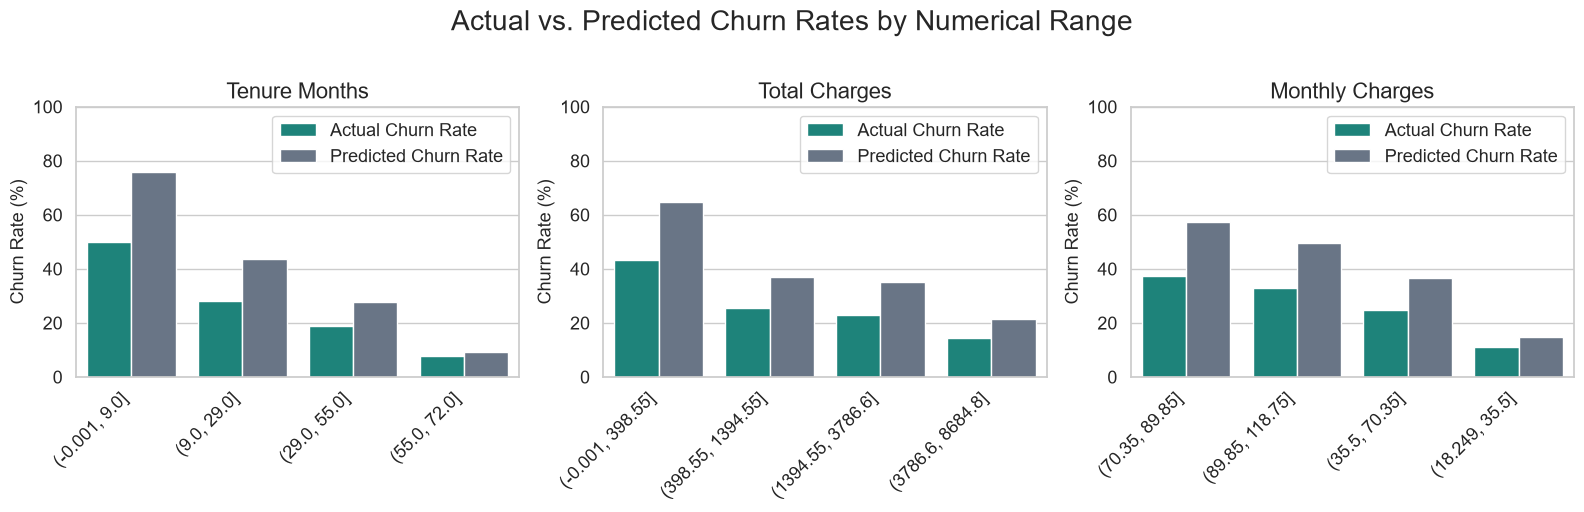

In [264]:
# visualize differences in actual and predicted in-group churn rates for each category

sns.set_theme(style = "whitegrid")

# Column names
variable_col = "Variable"
numerical_col = "Range"
actual_col = "Actual Churn Rate of Group (%)"
predicted_col = "Predicted Churn Rate of Group (%)"

# Identify variables to plot
variables = numerical_group_table[variable_col].unique()

# Matrix layout
n_cols = 3
n_rows = (len(variables) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize = (16, 5 * n_rows),
    squeeze = False
)

axes = axes.flatten()

for i, variable in enumerate(variables):
    ax = axes[i]

    plot_data = numerical_group_table[
        numerical_group_table[variable_col] == variable
    ].copy()

    # Sort categories by actual churn rate
    plot_data = plot_data.sort_values(
        by = actual_col,
        ascending = False
    )

    # Reshape data for grouped bars
    plot_data = plot_data.melt(
        id_vars = [numerical_col],
        value_vars = [actual_col, predicted_col],
        var_name = "Churn Type",
        value_name = "Churn Rate (%)"
    )

    plot_data["Churn Type"] = plot_data["Churn Type"].map({
        actual_col: "Actual Churn Rate",
        predicted_col: "Predicted Churn Rate"
    })

    sns.barplot(
        data=plot_data,
        x = numerical_col,
        y = "Churn Rate (%)",
        hue = "Churn Type",
        hue_order = ["Actual Churn Rate", "Predicted Churn Rate"],
        palette = palette,
        ax = ax
    )

    ax.set_title(f"{variable}", fontsize = 16)
    ax.set_xlabel("", fontsize = 13)
    ax.set_ylabel("Churn Rate (%)", fontsize = 13)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize = 13, rotation = 45)
    ax.tick_params(axis="y", labelsize = 13)
    ax.legend(title="", fontsize=13)

    # Align category labels
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Remove unused subplots
for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Actual vs. Predicted Churn Rates by Numerical Range",
    fontsize=20,
    y=1.02
)

plt.tight_layout()
plt.show()

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

This table accomplishes two things. First, it allows for a direct comparison of the actual churn counts and percentages (against the entire dataset) with that of the random forests-generated predictions. Again, the model appears to overpredict churn, particularly at the higher churn percentages. For example, 923 customers with tenures less than 9 months churned (13.1%), but the model predicted 1404 customers (19.9%). Second, this table shows how much each category or group contributes to churn. Customers with tenures of less than 9 months contribute to 13.1% of overall churn.

## Identifying Customer Types via Clustering (K-prototype)

The K-prototype method was selected because of it was designed to handle a mixture of categorical and numerical data.

In [265]:
df2.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,rf_prob,rf_pred
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,86,3239,Competitor made better offer,0.635,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1,67,2701,Moved,0.824,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500,1,86,5372,Moved,0.701,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050,1,84,5003,Moved,0.421,0
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300,1,89,5340,Competitor had better devices,0.480,0


In [266]:
# prepare data frame for clustering

df2kx = df2.copy()

df2kx = df2kx.drop(columns = ["Churn Value", "Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred"])

df2kx.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300


In [267]:
# index the columns based on position

catColumnsPos = [df2kx.columns.get_loc(col) for col in list(df2kx.select_dtypes('object').columns)]
print('Categorical columns           : {}'.format(list(df2kx.select_dtypes('object').columns)))
print('Categorical columns position  : {}'.format(catColumnsPos))

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# Towards Data Science. 
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Categorical columns           : ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']
Categorical columns position  : [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


C:\Users\mlmug\AppData\Local\Temp\ipykernel_40784\3267335530.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
C:\Users\mlmug\AppData\Local\Temp\ipykernel_40784\3267335530.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes f

In [268]:
# convert data frame to a matrix

df2Matrix = df2kx.to_numpy()

Cluster initiation: 1
Cluster initiation: 2
Cluster initiation: 3
Cluster initiation: 4
Cluster initiation: 5
Cluster initiation: 6
Cluster initiation: 7
Cluster initiation: 8
Cluster initiation: 9


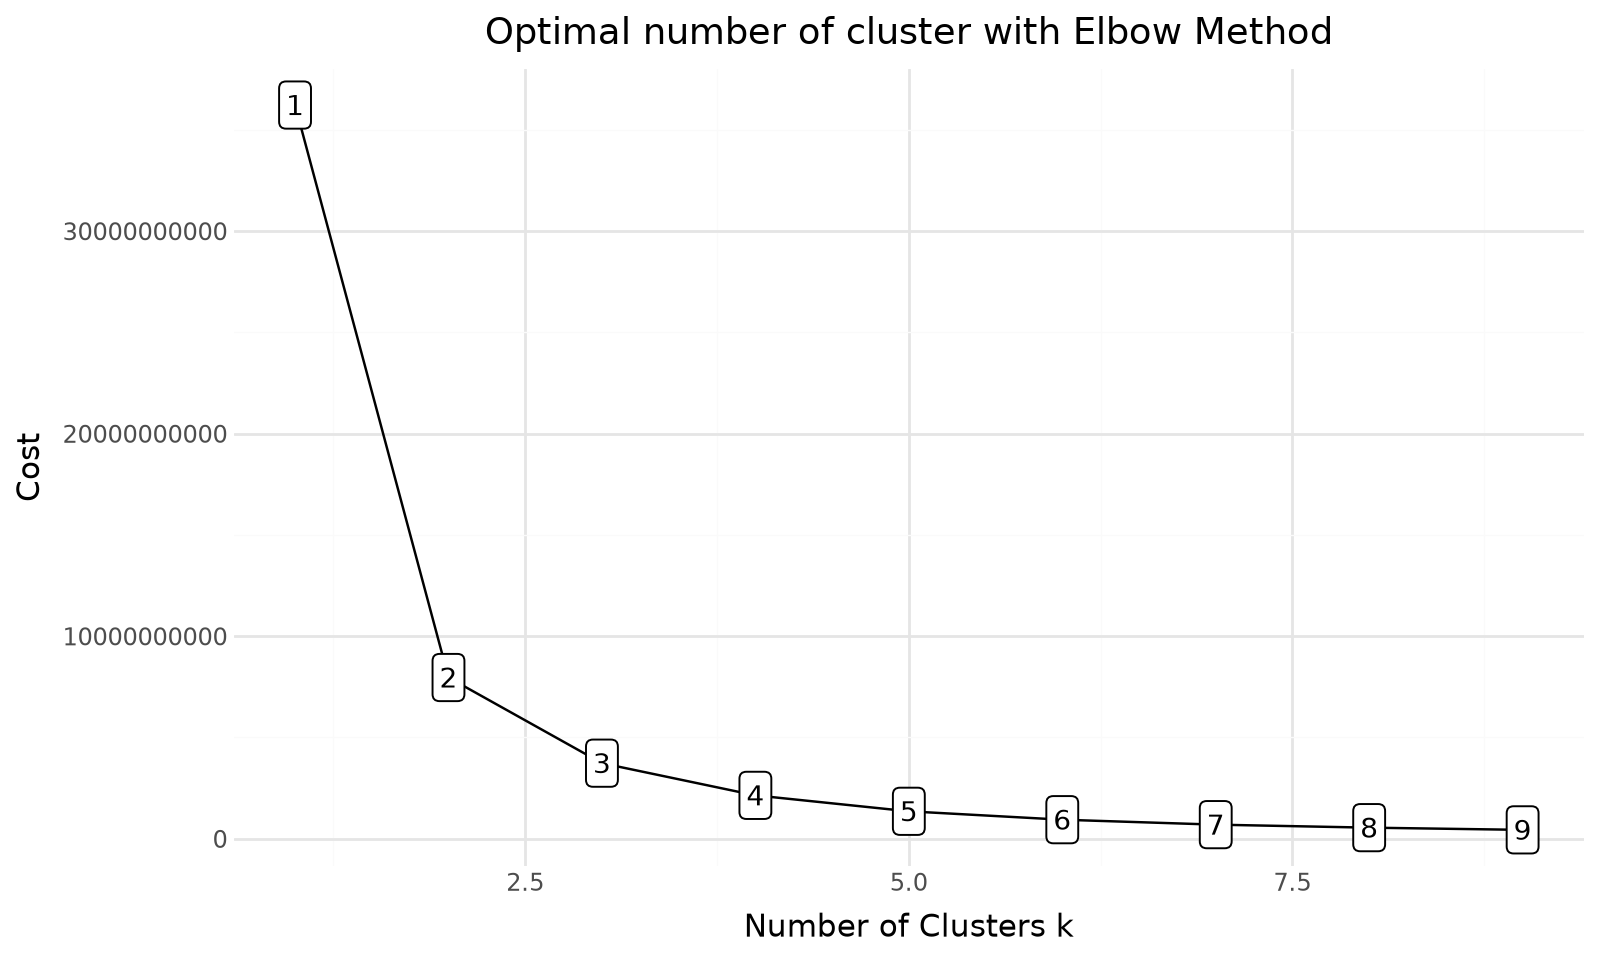

In [269]:
# Choose optimal K using Elbow method

cost = []

for cluster in range(1, 10):
    try:
        kprototype = KPrototypes(n_jobs = -1, n_clusters = cluster, init = 'Huang', random_state = 0)
        kprototype.fit_predict(df2Matrix, categorical = catColumnsPos)
        cost.append(kprototype.cost_)
        print('Cluster initiation: {}'.format(cluster))
    except:
        break
# Converting the results into a dataframe and plotting them
df2_cost = pd.DataFrame({'Cluster':range(1, 10), 'Cost':cost})
# Data viz
plotnine.options.figure_size = (8, 4.8)
(
    ggplot(data = df2_cost)+
    geom_line(aes(x = 'Cluster',
                  y = 'Cost'))+
    geom_point(aes(x = 'Cluster',
                   y = 'Cost'))+
    geom_label(aes(x = 'Cluster',
                   y = 'Cost',
                   label = 'Cluster'),
               size = 10,
               nudge_y = 1000) +
    labs(title = 'Optimal number of cluster with Elbow Method')+
    xlab('Number of Clusters k')+
    ylab('Cost')+
    theme_minimal()
)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# Towards Data Science. 
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

In [270]:
# # Fit to k = 2 clusters
# kprototype2 = KPrototypes(n_jobs = -1, n_clusters = 2, init = 'Huang', random_state = 0)
# k2pred = kprototype2.fit_predict(df2Matrix, categorical = catColumnsPos)

# # Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# # Towards Data Science. 
# # https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

In [271]:
# print("Clusters:", kprototype2.n_clusters)

# # Cluster centorid
# kprototype2.cluster_centroids_
# print(kprototype2.cluster_centroids_)

# # Check the iteration of the clusters created
# kprototype2.n_iter_
# print("Number of iterations:", kprototype2.n_iter_)

# print("Cost:", kprototype2.cost_)

# # Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# # Towards Data Science. 
# # https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

In [272]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# from kmodes.kprototypes import KPrototypes
# from sklearn.metrics import silhouette_score

# X = np.asarray(df2Matrix)
# cat_cols_pos = list(catColumnsPos)

# n = len(X)
# sample_size = min(2000, n)

# rng = np.random.default_rng(0)
# sample_idx = np.sort(
#     rng.choice(n, size=sample_size, replace=False)
# )

# X_sample = X[sample_idx]

# # Separate numerical and categorical columns
# num_cols_pos = [
#     i for i in range(X.shape[1])
#     if i not in cat_cols_pos
# ]

# X_num = X_sample[:, num_cols_pos].astype(float)
# X_cat = X_sample[:, cat_cols_pos]

# # Build mixed-data dissimilarity matrix
# num_dist = np.zeros((sample_size, sample_size))

# for j in range(X_num.shape[1]):
#     diff = X_num[:, j, None] - X_num[None, :, j]
#     num_dist += diff ** 2

# cat_dist = np.zeros_like(num_dist)

# for j in range(X_cat.shape[1]):
#     cat_dist += (
#         X_cat[:, j, None] != X_cat[None, :, j]
#     )

# # Fit k=2 first to obtain gamma
# base_model = KPrototypes(
#     n_jobs=-1,
#     n_clusters=2,
#     init="Huang",
#     random_state=0
# )

# base_model.fit_predict(X, categorical=cat_cols_pos)

# distance_matrix = num_dist + base_model.gamma * cat_dist
# np.fill_diagonal(distance_matrix, 0)

# # Compare silhouette scores
# results = []

# for k in range(2, 7):
#     model = KPrototypes(
#         n_jobs=-1,
#         n_clusters=k,
#         init="Huang",
#         random_state=0
#     )

#     labels = model.fit_predict(X, categorical=cat_cols_pos)
#     sample_labels = labels[sample_idx]

#     score = silhouette_score(
#         distance_matrix,
#         sample_labels,
#         metric="precomputed"
#     )

#     results.append({
#         "k": k,
#         "Silhouette Score": score
#     })

# silhouette_results = pd.DataFrame(results)

# display(
#     silhouette_results.style.format({
#         "Silhouette Score": "{:.3f}"
#     })
# )

# # Plot silhouette scores
# sns.set_theme(style="whitegrid")

# plt.figure(figsize=(8, 5))

# sns.lineplot(
#     data=silhouette_results,
#     x="k",
#     y="Silhouette Score",
#     marker="o",
#     markersize=8
# )

# plt.title("Mixed-Data Silhouette Score by Number of Clusters")
# plt.xlabel("Number of Clusters (k)")
# plt.ylabel("Silhouette Score")
# plt.xticks(range(2, 7))
# plt.tight_layout()
# plt.show()

In [273]:
# from kmodes.kprototypes import KPrototypes
# from kmodes import kprototypes
# from sklearn.metrics import silhouette_score
# import pandas as pd
# import numpy as np


# # create mixed-data distance matrix
# def create_dm(dataset, categorical, gamma):
#     total_nd = len(dataset)
#     distance_matrix = np.zeros((total_nd, total_nd))

#     categorical = set(categorical)
#     numerical = [
#         i for i in range(dataset.shape[1])
#         if i not in categorical
#     ]

#     for i in range(n):
#         for j in range(i + 1, n):
#             num_dist = sum(
#                 (float(dataset[i, col]) - float(dataset[j, col])) ** 2
#                 for col in numerical
#             )

#             cat_dist = sum(
#                 dataset[i, col] != dataset[j, col]
#                 for col in categorical
#             )

#             distance = num_dist + gamma * cat_dist
#             distance_matrix[i, j] = distance
#             distance_matrix[j, i] = distance

#     return distance_matrix

# # Use your existing matrix and model
# X = np.asarray(df2Matrix)
# gamma = kprototype2.gamma

# distance_matrix = create_dm(
#     X,
#     catColumnsPos,
#     gamma
# )

# # calculate silhouette scores for k = 2-10
# silhouette_scores = {}

# #distance_matrix=create_dm(df2Matrix)
# for k in range(2, 11):
#     model = KPrototypes(n_jobs = -1, n_clusters = cluster, init = 'Huang', random_state = 0)
#     cluster_labels = kprototype.fit_predict(df2Matrix, categorical = catColumnsPos)
#     score=silhouette_score(distance_matrix, cluster_labels,metric="precomputed")
#     silhouette_scores[k]=score
# print("The k and associated Silhouette scores are: ",silhouette_scores)

# # Convert results to a DataFrame
# silhouette_results = pd.DataFrame(
#     list(silhouette_scores.items()),
#     columns=["k", "Silhouette Score"]
# )

# # Plot
# sns.set_theme(style="whitegrid")
# plt.figure(figsize=(8, 5))

# sns.lineplot(
#     data=silhouette_results,
#     x="k",
#     y="Silhouette Score",
#     marker="o",
#     markersize=8
# )

# plt.title("Mixed-Data Silhouette Score by Number of Clusters")
# plt.xlabel("Number of Clusters (k)")
# plt.ylabel("Silhouette Score")
# plt.xticks(range(2, 10))
# plt.tight_layout()
# plt.show()

In [274]:
# Calculate silhouette scores for each model
silhouette_scores = {}

# k = 2
kprototype2 = KPrototypes(
    n_jobs=-1, n_clusters=2, init="Huang", random_state=0
)
k2pred = kprototype2.fit_predict(
    df2Matrix, categorical=catColumnsPos
)
silhouette_scores[2] = silhouette_score(
    distance_matrix, k2pred, metric="precomputed"
)

# k = 3
kprototype3 = KPrototypes(
    n_jobs=-1, n_clusters=3, init="Huang", random_state=0
)
k3pred = kprototype3.fit_predict(
    df2Matrix, categorical=catColumnsPos
)
silhouette_scores[3] = silhouette_score(
    distance_matrix, k3pred, metric="precomputed"
)

# k = 4
kprototype4 = KPrototypes(
    n_jobs=-1, n_clusters=4, init="Huang", random_state=0
)
k4pred = kprototype4.fit_predict(
    df2Matrix, categorical=catColumnsPos
)
silhouette_scores[4] = silhouette_score(
    distance_matrix, k4pred, metric="precomputed"
)

# k = 5
kprototype5 = KPrototypes(n_jobs=-1, n_clusters=5, init="Huang", random_state=0)
k5pred = kprototype5.fit_predict(df2Matrix, categorical=catColumnsPos)
silhouette_scores[5] = silhouette_score(distance_matrix, k5pred, metric="precomputed")

# k = 6
kprototype6 = KPrototypes(
    n_jobs=-1, n_clusters=6, init="Huang", random_state=0
)
k6pred = kprototype6.fit_predict(
    df2Matrix, categorical=catColumnsPos
)
silhouette_scores[6] = silhouette_score(
    distance_matrix, k6pred, metric="precomputed"
)

# Display results
print("The k and associated Silhouette scores are:", silhouette_scores)

silhouette_results = pd.DataFrame(
    list(silhouette_scores.items()),
    columns=["k", "Silhouette Score"]
)

display(silhouette_results)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 16, 2026, from https://chatgpt.com/

# Staff, C. (2022, December 2). Silhouette coefficient for k-modes and k-prototypes clustering. Coding Infinite.
# https://codinginfinite.com/silhouette-coefficient-for-k-modes-and-k-prototypes-clustering/

The k and associated Silhouette scores are: {2: 0.8477852419004867, 3: 0.7989422643368799, 4: 0.7541116406820512, 5: 0.7506756202723366, 6: 0.750473770830101}


,k,Silhouette Score
0,2,0.848
1,3,0.799
2,4,0.754
3,5,0.751
4,6,0.750


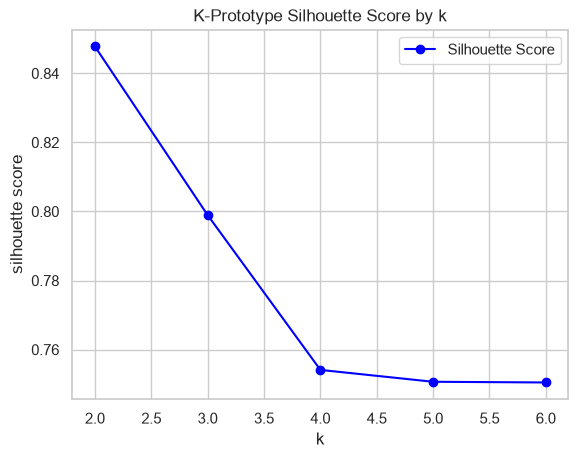

In [275]:
# plot silhouette_results

ax = silhouette_results.plot(
    x='k', y='Silhouette Score', kind='line', marker='o', linestyle='-', color='blue'
)

ax.set_xlabel('k')
ax.set_ylabel('silhouette score')
ax.set_title('K-Prototype Silhouette Score by k')

plt.show()

After analyzing the data by cost of clustering through the elbow plot, the silhouette scores were calculated for k = 2-6 to see if a higher number of clusters would lead to greater separation. Even though clustering on k = 2 clusters reduces the cost, k = 4 clusters offers better separation.

In [276]:
# Fit to k = 2 clusters
kprototype2 = KPrototypes(n_jobs = -1, n_clusters = 2, init = 'Huang', random_state = 0)
k2pred = kprototype2.fit_predict(df2Matrix, categorical = catColumnsPos)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# Towards Data Science. 
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

In [277]:
print("Clusters:", kprototype2.n_clusters)

# Cluster centorid
kprototype2.cluster_centroids_
print(kprototype2.cluster_centroids_)

# Check the iteration of the clusters created
kprototype2.n_iter_
print("Number of iterations:", kprototype2.n_iter_)

print("Cost:", kprototype2.cost_)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# Towards Data Science. 
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Clusters: 2
[['21.122094198504143' '53.58139276329088' '975.975530624621' 'Male' 'No'
  'No' 'No' 'Yes' 'No' 'DSL' 'No' 'No' 'No' 'No' 'No' 'No'
  'Month-to-month' 'Yes' 'Electronic check']
 ['58.9212786259542' '91.14954675572545' '5356.878697519079' 'Female'
  'No' 'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
  'Yes' 'Two year' 'Yes' 'Bank transfer (automatic)']]
Number of iterations: 6
Cost: 7953115004.732385


In [278]:
# Fit to k = 4 clusters
kprototype4 = KPrototypes(n_jobs = -1, n_clusters = 4, init = 'Huang', random_state = 0)
kprototype4.fit_predict(df2Matrix, categorical = catColumnsPos)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# Towards Data Science. 
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

array([1, 1, 1, ..., 3, 1, 3], shape=(7043,), dtype=uint16)

In [279]:
print("Clusters:", kprototype4.n_clusters)

# Cluster centorid
kprototype4.cluster_centroids_
print(kprototype4.cluster_centroids_)

# Check the iteration of the clusters created
kprototype4.n_iter_
print("Number of iterations:", kprototype4.n_iter_)

print("Cost:", kprototype4.cost_)

# Aprilliant, A. (2021, January 17). The k-prototype as clustering algorithm for mixed data type(Categorical and numerical). 
# Towards Data Science. 
# https://towardsdatascience.com/the-k-prototype-as-clustering-algorithm-for-mixed-data-type-categorical-and-numerical-fe7c50538ebb/

Clusters: 4
[['37.42300884955752' '62.82716814159291' '1936.7170206489723' 'Male'
  'No' 'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'No' 'No' 'No' 'No' 'No' 'No'
  'Month-to-month' 'Yes' 'Electronic check']
 ['11.993726474278544' '48.231602885821616' '422.30763801756194' 'Female'
  'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No'
  'Month-to-month' 'Yes' 'Mailed check']
 ['52.085930918281385' '82.6986941870262' '4171.905012636903' 'Male' 'No'
  'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
  'Month-to-month' 'Yes' 'Electronic check']
 ['66.28571428571429' '100.40991778006159' '6654.743422404943' 'Female'
  'No' 'Yes' 'No' 'Yes' 'Yes' 'Fiber optic' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
  'Yes' 'Two year' 'Yes' 'Bank transfer (automatic)']]
Number of iterations: 20
Cost: 2135287208.7990336


In [280]:
# Look at characteristics of the cluster centroids when k = 2

# Extract cluster centroids
centroids = kprototype2.cluster_centroids_

# Number of numerical columns
num_len = len(num_cols)

# Separate numerical and categorical centroids
num_centroids = centroids[:, :num_len]
cat_centroids = centroids[:, num_len:]

# Create DataFrames
df_num_centroids = pd.DataFrame(num_centroids, columns=num_cols)

df_cat_centroids = pd.DataFrame(cat_centroids, columns=cat_cols)

# Combine into one table
df_centroids2 = pd.concat([df_num_centroids, df_cat_centroids], axis=1)

# Add cluster labels
df_centroids2.index = [
    f"Cluster {i + 1}"
    for i in range(len(df_centroids2))
]

# Attach cluster assignments to original observations
df_eval2kx = df2.copy().reset_index(drop=True)
df_eval2kx = df_eval2kx.drop(columns = ["Churn Score", "CLTV", "Churn Reason"])
df_eval2kx['Cluster'] = kprototype2.labels_

# Calculate metrics
cluster_metrics2 = (
    df_eval2kx.groupby('Cluster')
    [['rf_prob', 'rf_pred', 'Churn Value']]
    .mean()
    .reindex([0, 1])
)

# Rename columns
cluster_metrics2.columns = [
    'Avg_RF_Probability',
    'Avg_RF_Prediction',
    'Actual_Churn_Rate'
]

# Reset centroid table index
df_centroids2 = df_centroids2.reset_index(drop=True)

# Assign metrics directly by row position
df_centroids2[cluster_metrics2.columns] = cluster_metrics2.to_numpy()

# Round numerical values to 2 decimal places
df_centroids2[num_cols] = df_centroids2[num_cols].astype(float).round(2)
df_centroids2[cluster_metrics2.columns] = (
    df_centroids2[cluster_metrics2.columns].round(2)
)

# Label clusters consistently
df_centroids2.index = ['Cluster 0', 'Cluster 1']

display(df_centroids2)

,Tenure Months,Monthly Charges,Total Charges,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Avg_RF_Probability,Avg_RF_Prediction,Actual_Churn_Rate
Cluster 0,21.120,53.580,975.980,Male,No,No,No,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,0.440,0.460,0.310
Cluster 1,58.920,91.150,5356.880,Female,No,Yes,No,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),0.280,0.240,0.150


In [281]:
# Look at characteristics of the cluster centroids

# Extract cluster centroids
centroids = kprototype4.cluster_centroids_

# Number of numerical columns
num_len = len(num_cols)

# Separate numerical and categorical centroids
num_centroids = centroids[:, :num_len]
cat_centroids = centroids[:, num_len:]

# Create DataFrames
df_num_centroids = pd.DataFrame(num_centroids, columns=num_cols)

df_cat_centroids = pd.DataFrame(cat_centroids, columns=cat_cols)

# Combine into one table
df_centroids4 = pd.concat([df_num_centroids, df_cat_centroids], axis=1)

# Add cluster labels
df_centroids4.index = [
    f"Cluster {i + 1}"
    for i in range(len(df_centroids4))
]

# Attach cluster assignments to original observations
df_eval4kx = df2.copy().reset_index(drop=True)
df_eval4kx = df_eval4kx.drop(columns = ["Churn Score", "CLTV", "Churn Reason"])
df_eval4kx['Cluster'] = kprototype4.labels_

# Calculate metrics
cluster_metrics4 = (
    df_eval4kx.groupby('Cluster')
    [['rf_prob', 'rf_pred', 'Churn Value']]
    .mean()
    .reindex([0, 1, 2, 3])
)

# Rename columns
cluster_metrics4.columns = [
    'Avg_RF_Probability',
    'Avg_RF_Prediction',
    'Actual_Churn_Rate'
]

# Reset centroid table index
df_centroids4 = df_centroids4.reset_index(drop=True)

# Assign metrics directly by row position
df_centroids4[cluster_metrics4.columns] = cluster_metrics4.to_numpy()

# Round numerical values to 2 decimal places
df_centroids4[num_cols] = df_centroids4[num_cols].astype(float).round(2)
df_centroids4[cluster_metrics4.columns] = (
    df_centroids4[cluster_metrics4.columns].round(2)
)

# Label clusters consistently
df_centroids4.index = ['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3']

display(df_centroids4)

,Tenure Months,Monthly Charges,Total Charges,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Avg_RF_Probability,Avg_RF_Prediction,Actual_Churn_Rate
Cluster 0,37.420,62.830,1936.720,Male,No,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,0.350,0.340,0.230
Cluster 1,11.990,48.230,422.310,Female,No,No,No,Yes,No,No,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,0.490,0.530,0.360
Cluster 2,52.090,82.700,4171.910,Male,No,Yes,No,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,0.310,0.280,0.170
Cluster 3,66.290,100.410,6654.740,Female,No,Yes,No,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),0.250,0.180,0.130


This clustering analysis, thus far, has created two clusters of customers. However, the power of these clusters is yet to be seen. The mode of the categorical columns and mean of the numerical columns within each cluster are shown above.

In [282]:
# # Copy df2 and attach cluster labels
# df_churn_stats = df2.copy().drop(columns = ["Churn Score", "CLTV", "Churn Reason"])
# df_churn_stats['Cluster'] = kprototype4.labels_

# # Calculate mode
# # def get_mode(x):
# #     modes = x.mode()
# #     return ', '.join(map(str, modes.tolist()))


# # Summary statistics for actual and predicted churn
# churn_summary = df_churn_stats.groupby('Cluster').agg(
#     Cluster_Count=('Churn Value', 'count'),
#     Actual_Churn_Mean=('Churn Value', 'mean'),
#     Total_Actual_Churn = ('Churn Value', 'sum'),
#     #Predicted_Churn_Count=('rf_pred', 'count'),
#     Predicted_Churn_Mean=('rf_pred', 'mean'),
#     Total_Predicted_Churn = ('rf_pred', 'sum')
# )

# display(churn_summary.round(3))

In [283]:
# Overall churn statistics (without clustering)

total_customers = len(df2)

actual_churn_count = df2['Churn Value'].sum()
predicted_churn_count = df2['rf_pred'].sum()

unclustered_summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Actual Churn Count',
        'Actual Churn Rate (%)',
        'Predicted Churn Count',
        'Predicted Churn Rate (%)'
    ],
    'Value': [
        total_customers,
        actual_churn_count,
        df2['Churn Value'].mean() * 100,
        predicted_churn_count,
        df2['rf_pred'].mean() * 100
    ]
})

display(unclustered_summary.round(2))

,Metric,Value
0,Total Customers,7043.000
1,Actual Churn Count,1869.000
2,Actual Churn Rate (%),26.540
3,Predicted Churn Count,2791.000
4,Predicted Churn Rate (%),39.630


In [284]:
# Attach k = 2 cluster labels to the original data

df_clustered2 = df2.copy().reset_index(drop=True)
df_clustered2['Cluster'] = kprototype2.labels_

# Calculate churn statistics by cluster
clustered_summary2 = df_clustered2.groupby('Cluster').agg(
    **{
    "Customer Count": ('Churn Value', 'size'),
    "Actual Churn Count": ('Churn Value', 'sum'),
    "Actual Churn Rate (%)": ('Churn Value', 'mean'),
    "Predicted Churn Count": ('rf_pred', 'sum'),
    "Predicted Churn Rate (%)": ('rf_pred', 'mean')
    }
)

# Convert rates to percentages
clustered_summary2[
    ['Actual Churn Rate (%)', 'Predicted Churn Rate (%)']
] *= 100

clustered_summary2 = clustered_summary2.round(1)

#display(clustered_summary2)

display(
    clustered_summary2.style.format({
        "Customer Count": "{:.0f}",
        "Actual Churn Count": "{:.0f}",
        "Actual Churn Rate (%)": "{:.1f}",
        "Predicted Churn Count": "{:.0f}",
        "Predicted Churn Rate (%)": "{:.1f}"
    })
)

,Customer Count,Actual Churn Count,Actual Churn Rate (%),Predicted Churn Count,Predicted Churn Rate (%)
Cluster,,,,,
0,4947,1547,31.3,2298,46.5
1,2096,322,15.4,493,23.5


In [285]:
# Attach k = 4 cluster labels to the original data

df_clustered4 = df2.copy().reset_index(drop=True)
df_clustered4['Cluster'] = kprototype4.labels_

# Calculate churn statistics by cluster
clustered_summary4 = df_clustered4.groupby('Cluster').agg(
    **{
    "Customer Count": ('Churn Value', 'size'),
    "Actual Churn Count": ('Churn Value', 'sum'),
    "Actual Churn Rate (%)": ('Churn Value', 'mean'),
    "Predicted Churn Count": ('rf_pred', 'sum'),
    "Predicted Churn Rate (%)": ('rf_pred', 'mean')
    }
)

# Convert rates to percentages
clustered_summary4[
    ['Actual Churn Rate (%)', 'Predicted Churn Rate (%)']
] *= 100

clustered_summary4 = clustered_summary4.round(1)

#display(clustered_summary4)

display(
    clustered_summary4.style.format({
        "Customer Count": "{:.0f}",
        "Actual Churn Count": "{:.0f}",
        "Actual Churn Rate (%)": "{:.1f}",
        "Predicted Churn Count": "{:.0f}",
        "Predicted Churn Rate (%)": "{:.1f}"
    })
)

,Customer Count,Actual Churn Count,Actual Churn Rate (%),Predicted Churn Count,Predicted Churn Rate (%)
Cluster,,,,,
0,1695,385,22.7,582,34.3
1,3188,1150,36.1,1698,53.3
2,1187,205,17.3,336,28.3
3,973,129,13.3,175,18.0


In [286]:
# Order the cluster

dfk2 = df_clustered2.copy()
dfk2['Cluster'] = dfk2['Cluster'].astype('category')

dfk4 = df_clustered4.copy()
dfk4['Cluster'] = dfk4['Cluster'].astype('category')

dfk4.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,rf_prob,rf_pred,Cluster
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1,86,3239,Competitor made better offer,0.635,1,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1,67,2701,Moved,0.824,1,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.500,1,86,5372,Moved,0.701,1,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.800,3046.050,1,84,5003,Moved,0.421,0,0
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.700,5036.300,1,89,5340,Competitor had better devices,0.480,0,2


In [290]:
# look at overall purity across multiple columns, k = 2

purity_by_column2 = {}

columns_to_check = dfk2.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

for col in columns_to_check:
    table = pd.crosstab(dfk2['Cluster'], dfk2[col])

    purity_by_column2[col] = (
        table.max(axis=1).sum() / table.values.sum()
        if table.values.sum() > 0 else 0
    )

overall_purity2 = sum(purity_by_column2.values()) / len(purity_by_column2)

print(f"\nAverage overall purity, k = 2: {overall_purity2:.2%}")

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/


Average overall purity, k = 2: 52.04%


In [291]:
# look at overall purity across multiple columns, k = 4

purity_by_column4 = {}

columns_to_check = dfk4.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

for col in columns_to_check:
    table = pd.crosstab(dfk4['Cluster'], dfk4[col])

    purity_by_column4[col] = (
        table.max(axis=1).sum() / table.values.sum()
        if table.values.sum() > 0 else 0
    )

overall_purity4 = sum(purity_by_column4.values()) / len(purity_by_column4)

print(f"\nAverage overall purity, k = 4: {overall_purity4:.2%}")

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/


Average overall purity, k = 4: 52.54%


In [294]:
# look at column purity by each cluster, k = 2

# Specify categorical columns to evaluate
columns_to_check = dfk2.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

purityk_results2 = []

for col in columns_to_check:
    row = {'Feature': col}

    for cluster in [0, 1]:
        subset = dfk2[dfk2['Cluster'] == cluster]
        counts = subset[col].value_counts() # count of most frequent category

        row[f'Cluster {cluster} Majority'] = (
            counts.idxmax() if not counts.empty else None
        )
        row[f'Cluster {cluster} Purity'] = (
            counts.max() / len(subset) if len(subset) and not counts.empty else 0 # total observations in cluster
        )

    purityk_results2.append(row)

df_purityk_wide2 = pd.DataFrame(purityk_results2)

purity_cols2 = [
    'Cluster 0 Purity',
    'Cluster 1 Purity',
    'Combined Purity, k = 2'
]

# Format purity as percentages
df_purityk_wide2['Cluster 0 Purity'] = (
    df_purityk_wide2['Cluster 0 Purity']
)

df_purityk_wide2['Cluster 1 Purity'] = (
    df_purityk_wide2['Cluster 1 Purity']
)

combined_purity2 = []

for col in columns_to_check:
    table = pd.crosstab(dfk2['Cluster'], dfk2[col])

    purity = table.max(axis=1).sum() / table.values.sum()

    combined_purity2.append(purity)

df_purityk_wide2['Combined Purity, k = 2'] = combined_purity2

df_purityk_wide2[purity_cols2] = (
    df_purityk_wide2[purity_cols2] * 100
).round(1)

display(df_purityk_wide2)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Feature,Cluster 0 Majority,Cluster 0 Purity,Cluster 1 Majority,Cluster 1 Purity,"Combined Purity, k = 2"
0,Gender,Male,50.700,Female,50.000,50.500
1,Senior Citizen,No,85.900,No,78.800,83.800
2,Partner,No,60.200,Yes,68.500,62.700
3,Dependents,No,77.300,No,75.900,76.900
4,Tenure Months,1,12.400,72,14.000,12.900
5,Phone Service,Yes,88.200,Yes,95.400,90.300
6,Multiple Lines,No,58.700,Yes,72.300,62.800
7,Internet Service,DSL,34.800,Fiber optic,66.700,44.300
8,Online Security,No,51.300,Yes,54.200,52.100
9,Online Backup,No,48.600,Yes,67.400,54.200


In [297]:
# look at column purity by each cluster, k = 4

# Specify categorical columns to evaluate
columns_to_check = dfk4.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "Cluster"])

purityk_results4 = []

for col in columns_to_check:
    row = {'Feature': col}

    for cluster in [0, 1, 2, 3]:
        subset = dfk4[dfk4['Cluster'] == cluster]
        counts = subset[col].value_counts() # count of most frequent category

        row[f'Cluster {cluster} Majority'] = (
            counts.idxmax() if not counts.empty else None
        )
        row[f'Cluster {cluster} Purity'] = (
            counts.max() / len(subset) if len(subset) and not counts.empty else 0 # total observations in cluster
        )

    purityk_results4.append(row)

df_purityk_wide4 = pd.DataFrame(purityk_results4)

purity_cols4 = [
    'Cluster 0 Purity',
    'Cluster 1 Purity',
    'Cluster 2 Purity',
    'Cluster 3 Purity',
    'Combined Purity, k = 4'
]

# Format purity as percentages
df_purityk_wide4['Cluster 0 Purity'] = (
    df_purityk_wide4['Cluster 0 Purity']
)

df_purityk_wide4['Cluster 1 Purity'] = (
    df_purityk_wide4['Cluster 1 Purity']
)

df_purityk_wide4['Cluster 2 Purity'] = (
    df_purityk_wide4['Cluster 2 Purity']
)

df_purityk_wide4['Cluster 3 Purity'] = (
    df_purityk_wide4['Cluster 3 Purity']
)

combined_purity4 = []

for col in columns_to_check:
    table = pd.crosstab(dfk4['Cluster'], dfk4[col])

    purity = table.max(axis=1).sum() / table.values.sum()

    combined_purity4.append(purity)

df_purityk_wide4['Combined Purity, k = 4'] = combined_purity4

df_purityk_wide4[purity_cols4] = (
    df_purityk_wide4[purity_cols4] * 100
).round(1)

display(df_purityk_wide4)

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

,Feature,Cluster 0 Majority,Cluster 0 Purity,Cluster 1 Majority,Cluster 1 Purity,Cluster 2 Majority,Cluster 2 Purity,Cluster 3 Majority,Cluster 3 Purity,"Combined Purity, k = 4"
0,Gender,Male,52.500,Female,50.400,Male,50.700,Female,50.600,51.000
1,Senior Citizen,No,82.300,No,87.900,No,79.400,No,78.300,83.800
2,Partner,Yes,52.900,No,67.600,Yes,61.600,Yes,76.200,64.200
3,Dependents,No,76.500,No,77.900,No,76.900,No,74.200,76.900
4,Tenure Months,72,4.000,1,19.200,72,4.500,72,24.800,13.800
5,Phone Service,Yes,86.500,Yes,89.100,Yes,91.000,Yes,100.000,90.300
6,Multiple Lines,Yes,44.900,No,68.100,Yes,59.800,Yes,85.400,63.500
7,Internet Service,Fiber optic,40.500,No,37.100,Fiber optic,53.800,Fiber optic,81.300,46.900
8,Online Security,No,51.200,No,51.300,No,51.100,Yes,59.800,52.400
9,Online Backup,No,47.000,No,49.500,Yes,57.900,Yes,78.000,54.200


This data looks at each cluster and measures the purity or concentration of the most frequent category for each column. When looking at the Churn Value, the majority in Clusters 0 and 1 are non-churners, 69% and 85%, respectively. Additionally, the majority in the random forests-generated prediction are also non-churners, 54% and 76%, respectively. The majority of cluster purity measures are similar or even between the clusters, suggesting that they are not strong indicators of Cluster 0 or 1. For example, when examining gender, 50% of Cluster 0 are men and 50.5% of Cluster 1 are women. Therefore, gender is not a strong predictor of clustering. Similarly, 88% of customers in Cluster 0 have phone service, and 90% of customers in Cluster 1 have phone service as well. Again, this similarity is not useful in distinguishing between clusters.

## Identifying Customer Types via Association Rules

In [ ]:
df2a = df2.copy()
df2a = df2a.drop(columns = ["Churn Score", "CLTV", "Churn Reason", "rf_prob", "rf_pred"])

target = "Churn Value"
cat_cols = ["Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Multiple Lines", "Internet Service", 
"Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies", "Contract", 
"Paperless Billing", "Payment Method"]
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

# Convert numerical variables to categorical intervals
for col in num_cols:
    df2a[col] = pd.qcut(
        df2a[col],
        q=4,
        duplicates="drop"
    )

# Convert predictors into categorical indicator variables
X = pd.get_dummies(
    df2a[cat_cols + num_cols].astype(str),
    dtype=bool
)

# Add the binary response as an item
X["Churn=1"] = df2a[target].eq(1)
X["Churn=0"] = df2a[target].eq(0)

# Find frequent itemsets
itemsets = apriori(
    X,
    min_support=0.02, # retain itemsets that appear in at least 2% of observations
    use_colnames=True,
    max_len=3 # consider itemsets containing up to 3 items
)

# Generate association rules
rules = association_rules(
    itemsets,
    metric="confidence",
    min_threshold=0.7 # retain rules with at least 70% confidence
)

# Retain only rules predicting Churn=1
positive_rules = rules[
    rules["consequents"].apply(
        lambda s: s == frozenset(["Churn=1"])
    )
]

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)


positive_rules.sort_values(
        "lift", ascending=False
    )[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(40)

# Shmueli, G., Bruce, P. C., Gedeck, P., & Patel, N. R. (2025). Machine learning for business analytics (2nd ed.). 
# Wiley-Blackwell. https://bookshelf.vitalsource.com/books/9781394286805

# Chatgpt. (n.d.). ChatGPT. Retrieved October 11, 2026, from https://chatgpt.com/

In [ ]:
# total number of rules
print("Total rules:", len(rules))

# total number of rules predicting churn
print("Churn rules:", len(positive_rules))

# total number of rules with confidence >= 0.70 and lift >= 1.5
filtered_rules = positive_rules[
    (positive_rules["confidence"] >= 0.70) &
    (positive_rules["lift"] >= 1.5)
]

print("Filtered churn rules:", len(filtered_rules))

The analysis via association has revealed 3 rules with low support (<0.1), high confidence (>0.70), and high lift (>2). This suggests that these rules are specific enough that the combination of the three listed variables in the antecedent leads to a consequent of churn = 1.